# <u>Partie 1 : Data Quality</u>

**<u>Objectif</u>** 

L'objectif de cette partie est de recenser, chiffrer et corriger les anomalies des tables *Contrats*, *Stripe* et *Remboursements* avant de calculer les statistiques de la partie 2.

**<u>Démarche</u>**

1. Chargement des données brutes
2. Profil rapide de chaque table
3. Recensement des anomalies, consignées dans un **registre unique** :
   formats, structure, clés, intégrité référentielle (en SQL), cohérence temporelle entre tables (en SQL), qualité interne de chaque table
4. Analyse chiffrée (volumes, pourcentages, montants en jeu) et graphiques
5. Nettoyage et export des tables propres utilisées dans les parties 2 à 4

**<u>Principe de nettoyage</u>** 

On ne supprime que ce qui est inexploitable (lignes vides, lignes corrompues, doublons). On corrige ce qui peut l'être sans ambiguïté (types, formats, libellés, doublons de clé). On corrige ce qui peut l’être sans ambiguïté (types, formats, libellés, doublons de clé). Tout le reste est conservé et signalé par un indicateur pour que chaque analyse décide en connaissance de cause plutôt que de perdre l’information.

**<u>Date de référence</u>** 

 Le 19/10/2026 est la date de la dernière clôture d’un contrat fermé et de la dernière décision de remboursement : on la considère comme la date d’extraction.

## <u>Chargement des packages requis</u> 

In [1]:
import re
import sqlite3
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.config import DATE_EXTRACTION, DATE_MIGRATION, DATES_SIGNATURE_DEFAUT, DOSSIER_PROPRE, FICHIER_BRUT
from src.style import ENCRE, PALETTE, STATUT, appliquer_style, etiqueter_barres, format_milliers, format_pct, nb, sauver

appliquer_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
UUID = r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}"

**UUID** : motif des identifiants (ex. `9cb148b9-5dd5-4353-88df-d9d463d460ea`), utilisé pour extraire les bénéficiaires de `list_beneficiaries_id`.

## 1. <u>Chargement des données brutes</u>

Le fichier excel contient 4 feuilles.

In [2]:
feuilles = pd.read_excel(FICHIER_BRUT, sheet_name=None)
contrats_brut = feuilles["Contrats"]
remb_brut = feuilles["remboursements"]
stripe_brut = feuilles["Stripe"]
produits_brut = feuilles["product_rows"]

pd.DataFrame({nom: {"lignes": df.shape[0], "colonnes": df.shape[1]} for nom, df in feuilles.items()}).T

,lignes,colonnes
Contrats,12484,19
remboursements,55522,11
product_rows,58,5
Stripe,166373,16


## <u>Découverte des données brutes</u>

### Table Contrats

In [3]:
contrats_brut.columns

Index(['gender', 'beneficiary_individual_type', 'created_at', 'birthdate',
       'professional_status', 'beneficiary_id', 'product_id', 'price',
       'frequency', 'start_date', 'user_id', 'list_beneficiaries_id',
       'signature_date', 'address_zip', 'address_city', 'source', 'Contrat_id',
       'Closed_Date', 'Status_contrat'],
      dtype='str')

In [4]:
contrats_brut.head()

,gender,beneficiary_individual_type,created_at,birthdate,professional_status,beneficiary_id,product_id,price,frequency,start_date,user_id,list_beneficiaries_id,signature_date,address_zip,address_city,source,Contrat_id,Closed_Date,Status_contrat
0,FEMALE,PRIMARY_SUBSCRIBER,2025-06-03 09:03:55.654703+00,1985-04-18,SELF_EMPLOYED,d3fd8bbe-0a20-4231-944e-4ec62d9f2259,9cb148b9-5dd5-4353-88df-d9d463d460ea,75.33,MONTHLY,2023-09-01,517ac6b8-797d-4b19-a8be-6ce008e29082,"[""d3fd8bbe-0a20-4231-944e-4ec62d9f2259""]",2024-08-05,33 000.00,BORDEAUX,NaN,f964652a-75a5-49ab-afb5-b6730ecd69d0,2026-09-09 02:15:44,Contrat en cours
1,FEMALE,PRIMARY_SUBSCRIBER,2025-07-05 17:25:03.425+00,2004-06-05,STUDENT,7dcaac69-5947-48c5-af1d-e7413aa22237,9b6eb076-2ac2-4b9a-882a-10603d6e8cf7,136.03,MONTHLY,2025-07-05,c7467f76-8fd5-4e7e-8547-d6dd9a7d8d76,"[""7dcaac69-5947-48c5-af1d-e7413aa22237"",""0f027934-eac3-4d7c-87ff-7...",2025-07-05,13 016.00,MARSEILLE,NaN,9a50a420-d269-4733-8854-e45148c89c64,2026-02-02 10:59:04,Contrat Fermé
2,FEMALE,PRIMARY_SUBSCRIBER,2026-10-14 13:19:28.456953+00,1994-04-03,SELF_EMPLOYED,5822a408-b121-4107-96c2-1180b99bb103,b06bd9f5-73e4-4103-83a2-dbde8bb361e1,87.69,MONTHLY,2026-10-14,3d547c9a-1c7d-495a-ba6c-8721423b79d9,"[""5822a408-b121-4107-96c2-1180b99bb103""]",2026-10-14,13 004.00,Marseille,adwords,4e440b50-77b0-4654-9622-472a3445c850,2026-10-16 01:00:01,Contrat en cours
3,MALE,PRIMARY_SUBSCRIBER,2025-06-03 09:06:17.738584+00,1995-03-01,NaN,63ed3515-7a68-42b7-a1d3-ca5fe822eb6c,62cf29fb-2956-4413-8b5e-24c91a56e4d4,26.43,MONTHLY,2023-12-01,3fed6cca-bcaa-4f3b-b874-c6f8f4dc6f87,"[""63ed3515-7a68-42b7-a1d3-ca5fe822eb6c""]",2021-08-13,70 000.00,ANDELARRE,NaN,71cccf19-5f81-49c4-a67d-4eaf194f9851,2026-06-08 08:54:29,Contrat Fermé
4,MALE,PRIMARY_SUBSCRIBER,2025-06-03 09:49:05.053689+00,1983-04-23,NaN,ab5dabdd-8578-426b-8b1d-e3e9d7bdd8b8,62cf29fb-2956-4413-8b5e-24c91a56e4d4,53.49,MONTHLY,2025-03-16,700b86a1-e523-413f-98cb-7fdca3da3339,"[""ab5dabdd-8578-426b-8b1d-e3e9d7bdd8b8""]",2025-03-16,37 390.00,ST ROCH,NaN,66807f2c-00ec-4bbd-9997-e4ef3127f833,2026-09-16 15:00:13,Contrat en cours


In [5]:
contrats_brut.tail()

,gender,beneficiary_individual_type,created_at,birthdate,professional_status,beneficiary_id,product_id,price,frequency,start_date,user_id,list_beneficiaries_id,signature_date,address_zip,address_city,source,Contrat_id,Closed_Date,Status_contrat
12479,FEMALE,PRIMARY_SUBSCRIBER,2026-07-20 14:15:42.171965+00,1996-02-27,JOB_SEEKER,50ae36e0-da48-487e-97fb-558e3a12315f,62cf29fb-2956-4413-8b5e-24c91a56e4d4,44.52,MONTHLY,2026-10-01,76fa0c7d-5983-412d-b115-0c367bbd4f7c,"[""50ae36e0-da48-487e-97fb-558e3a12315f""]",2026-07-20,49 130.00,Sainte-Gemmes-sur-Loire,NaN,38563d12-ecf5-4e52-9ed6-6283c5c250f1,2026-10-15,Contrat Fermé
12480,FEMALE,PRIMARY_SUBSCRIBER,2026-04-03 08:35:52.474515+00,1998-08-18,JOB_SEEKER,bd6dd813-315c-42f3-a4a4-45439bedebf8,62cf29fb-2956-4413-8b5e-24c91a56e4d4,42.87,MONTHLY,2026-04-03,e1b59119-3670-4ea2-a5f1-52278f35c1db,"[""bd6dd813-315c-42f3-a4a4-45439bedebf8""]",2026-04-03,46 400.00,Saint-Céré,Parrainage,17824392-b619-4f83-9373-16f7415f3434,2026-10-16,Contrat Fermé
12481,FEMALE,PRIMARY_SUBSCRIBER,2026-10-02 08:51:24.759796+00,1993-01-24,SELF_EMPLOYED,9407edbd-3326-41ba-923b-8cc6712d5e38,9cb148b9-5dd5-4353-88df-d9d463d460ea,68.30,MONTHLY,2026-10-02,9f1f8672-3069-4626-886e-dcd7410574f5,"[""9407edbd-3326-41ba-923b-8cc6712d5e38""]",2026-10-02,92 100.00,Boulogne-Billancourt,NaN,04d77086-5bf3-418a-83e7-1b8ab8f41dd3,2026-10-16,Contrat Fermé
12482,FEMALE,PRIMARY_SUBSCRIBER,2025-09-28 12:32:55.961791+00,2000-11-16,FONCTIONARY,a7d23b35-1227-47fb-9e5e-c2c4989fcace,62cf29fb-2956-4413-8b5e-24c91a56e4d4,41.12,MONTHLY,2025-09-28,ffe8576e-74d0-48da-ae80-2219e4815e0e,"[""a7d23b35-1227-47fb-9e5e-c2c4989fcace""]",2025-09-28,95 120.00,Ermont,Parrainage,86c1f594-426a-4aa5-a1ca-930b7ea8143a,2026-10-16,Contrat Fermé
12483,FEMALE,PRIMARY_SUBSCRIBER,2025-09-17 10:36:10.346595+00,1996-04-27,OTHER,ad421265-9277-43b3-980a-406e36312c69,62cf29fb-2956-4413-8b5e-24c91a56e4d4,44.52,MONTHLY,2025-09-07,fc7623dc-7055-4256-bef3-356b13193005,"[""ad421265-9277-43b3-980a-406e36312c69""]",2025-09-07,31 200.00,TOULOUSE,NaN,cbd69be9-01e9-4d0f-a0f4-7a259ca68f2a,2100-09-01,Contrat en cours


In [6]:
contrats_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 12484 entries, 0 to 12483
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   gender                       12484 non-null  str           
 1   beneficiary_individual_type  12484 non-null  str           
 2   created_at                   12484 non-null  str           
 3   birthdate                    12483 non-null  datetime64[us]
 4   professional_status          5776 non-null   str           
 5   beneficiary_id               12484 non-null  str           
 6   product_id                   12484 non-null  str           
 7   price                        12484 non-null  float64       
 8   frequency                    12484 non-null  str           
 9   start_date                   12484 non-null  datetime64[us]
 10  user_id                      12484 non-null  str           
 11  list_beneficiaries_id        12440 non-null  str    

### Table remboursement

In [7]:
remb_brut.columns

Index(['created_at', 'approved_date', 'beneficiary_id', 'is_approved',
       'comment', 'amount_ss', 'rest_to_pay', 'amount_request', 'contract_id',
       'amount_refund_mutual', 'reason'],
      dtype='str')

In [8]:
remb_brut.head()

,created_at,approved_date,beneficiary_id,is_approved,comment,amount_ss,rest_to_pay,amount_request,contract_id,amount_refund_mutual,reason
0,2026-06-04 13:57:40.919,2026-06-04,075c37f8-03cf-40f7-8570-26faf30e0c0f,1.00,NaN,NaN,40,65,dbb80bce-e2b2-47d2-ab7d-2dc2dfe1c9d4,25.00,NaN
1,2025-10-28 11:34:17.575,2025-10-28,27788c51-3cce-4575-b842-e445cef30ef4,1.00,NaN,NaN,0,49.52,79c310ed-26c0-4b91-8a4b-d0feef32f24a,49.52,NaN
2,2026-05-11 10:21:40.217,2026-05-11,fbb89226-683a-4a39-93f2-6f2458b33a39,1.00,NaN,NaN,16.8,66.8,6a1ac0ad-1b53-4496-9fc0-8d6728210698,50.00,NaN
3,2026-06-04 13:35:31.313,2026-06-04,54af5d9e-c148-44dd-91ae-838b1fb83104,0.00,Votre contrat ne prévoit pas le remboursement des actes HN (hors n...,NaN,NaN,NaN,NaN,NaN,HN
4,2026-05-11 10:32:56.319,2026-05-11,b34de4ef-1108-4f45-bdcc-0e6d69cc4b63,1.00,NaN,NaN,45,70,8a7804d3-6862-459d-9c88-abe59e19fb7c,25.00,NaN


In [9]:
remb_brut.tail()

,created_at,approved_date,beneficiary_id,is_approved,comment,amount_ss,rest_to_pay,amount_request,contract_id,amount_refund_mutual,reason
55517,2026-07-10 14:03:19.692,2026-07-10,d246d138-f9c5-4ad3-8e67-1dbe2b6263a2,1.00,NaN,NaN,25,65,ba662d5c-73e2-445b-b083-f10d679dfd00,40.00,NaN
55518,2026-03-06 10:39:48.195,2026-03-06,0a15878d-4ea7-4ade-95d8-434d136b113d,0.00,Nous ne pourrons pas procéder au remboursement de vos soins effect...,NaN,NaN,NaN,NaN,NaN,DATE FIN CONTRAT
55519,2026-05-18 10:44:11.172,2026-05-18,55948cc5-c8cd-4c3d-9c07-21dc2c377482,0.00,Ce montant est votre reste à charge après notre participation tier...,NaN,NaN,NaN,NaN,NaN,SOINS DÉJÀ RÉGLÉS
55520,2025-12-22 12:05:36.006,2025-12-22,1504be3e-1686-493a-8f44-859470517baa,1.00,NaN,21,0,30,6c4a710a-cd72-42ab-b168-6b6c7c9679df,9.00,NaN
55521,2025-12-12 14:29:48.060,2025-12-12,624b3aca-1422-4989-8e7c-e5a859e0151b,1.00,NaN,NaN,0,8.49,e308f9cc-78ca-48b3-897c-05ff0753d1a7,8.49,NaN


In [10]:
remb_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 55522 entries, 0 to 55521
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   created_at            53225 non-null  datetime64[us]
 1   approved_date         53222 non-null  datetime64[us]
 2   beneficiary_id        53572 non-null  str           
 3   is_approved           53221 non-null  float64       
 4   comment               13632 non-null  str           
 5   amount_ss             10862 non-null  str           
 6   rest_to_pay           42290 non-null  str           
 7   amount_request        39282 non-null  str           
 8   contract_id           47179 non-null  str           
 9   amount_refund_mutual  41226 non-null  float64       
 10  reason                9611 non-null   str           
dtypes: datetime64[us](2), float64(2), str(7)
memory usage: 4.7 MB


### Table Stripe

In [11]:
stripe_brut.columns 

Index(['Contract_id', 'product_id', 'Created date (UTC) Stripe', 'Amount',
       'Amount Refunded', 'Currency', 'Captured', 'Converted Amount',
       'Converted Amount Refunded', 'Converted Currency', 'Decline Reason',
       'Description', 'Refunded date (UTC)', 'Statement Descriptor', 'Status',
       'Seller Message'],
      dtype='str')

In [12]:
stripe_brut.head()

,Contract_id,product_id,Created date (UTC) Stripe,Amount,Amount Refunded,Currency,Captured,Converted Amount,Converted Amount Refunded,Converted Currency,Decline Reason,Description,Refunded date (UTC),Statement Descriptor,Status,Seller Message
0,fdbb2781-e037-4e86-8be8-4244014595d9,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45953 days 23:34:05,"35,23","0,00",eur,True,"35,23","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
1,138240da-32dc-4d13-8ec3-7c034db6c7b2,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45953 days 11:42:54,"35,84","0,00",eur,True,"35,84","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
2,2b984c56-7589-4750-b097-c3afbdb5a1c9,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45953 days 17:57:28,"36,13","0,00",eur,True,"36,13","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
3,6fd65d70-a84c-4142-b544-6c7ccc72ef6c,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45953 days 10:12:32,"36,33","0,00",eur,True,"36,33","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
4,ec5bdc45-cd7d-46c0-a5c5-770c403224b6,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45953 days 14:51:26,"37,24","0,00",eur,True,"37,24","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.


In [13]:
stripe_brut.tail()

,Contract_id,product_id,Created date (UTC) Stripe,Amount,Amount Refunded,Currency,Captured,Converted Amount,Converted Amount Refunded,Converted Currency,Decline Reason,Description,Refunded date (UTC),Statement Descriptor,Status,Seller Message
166368,9b062e0d-6e46-4954-adf7-fcea476664d5,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45839 days 22:09:45,"39,54","0,00",eur,True,"39,54","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
166369,57dd1b9b-b35d-4527-937c-b2a4a68c42cf,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45839 days 15:29:20,"39,54","0,00",eur,True,"39,54","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
166370,786a40e0-426e-42bd-9bb7-ca21f2854a30,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45839 days 09:50:34,"39,54","0,00",eur,True,"39,54","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
166371,c3628e9f-d287-4cfa-b360-a185fa0c93c2,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45839 days 05:19:43,"39,54","0,00",eur,True,"39,54","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.
166372,a9fad969-148f-4ccc-9eed-f377a83fd7e9,62cf29fb-2956-4413-8b5e-24c91a56e4d4,45839 days 02:06:05,"39,54","0,00",eur,True,"39,54","0,00",eur,NaN,Subscription update,NaT,NOSTRUMCARE,Paid,Payment complete.


In [14]:
stripe_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 166373 entries, 0 to 166372
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype          
---  ------                     --------------   -----          
 0   Contract_id                166373 non-null  str            
 1   product_id                 166373 non-null  str            
 2   Created date (UTC) Stripe  166373 non-null  timedelta64[us]
 3   Amount                     166373 non-null  str            
 4   Amount Refunded            166373 non-null  str            
 5   Currency                   166373 non-null  str            
 6   Captured                   166373 non-null  bool           
 7   Converted Amount           166373 non-null  str            
 8   Converted Amount Refunded  166373 non-null  str            
 9   Converted Currency         166373 non-null  str            
 10  Decline Reason             31324 non-null   str            
 11  Description                166297 non-null  str   

### Table produits

In [15]:
produits_brut.columns

Index(['id', 'name', 'insurer', 'universe', 'type'], dtype='str')

In [16]:
produits_brut.head()

,id,name,insurer,universe,type
0,1042d1b6-4bbc-49ca-9ce7-1aa51d75fea7,OBS4,MMC,HEALTH,SUPPLEMENTARY
1,1bcb1553-ce33-4ccf-ba1b-699d5d973c8b,TDMI 15000,HISCOX,PROFESSIONAL,PROFESSIONAL_LIABILITY
2,2998dcdc-74ed-431a-bb0f-3bbabcd9bcee,RENF OD 2,MMC,HEALTH,SUPPLEMENTARY
3,2a9596eb-86ab-461e-ba91-987664bd105d,Pack Petit Chagrin,MMC,HEALTH,SUPPLEMENTARY
4,30c13d1d-7b8d-4e93-8c83-2fba830e0ad8,OBS1,MMC,HEALTH,SUPPLEMENTARY


In [17]:
produits_brut.tail()

,id,name,insurer,universe,type
53,f1b1ef79-2010-4c7c-b708-0cb55b24848a,RENF HOSP 1,MMC,HEALTH,SUPPLEMENTARY
54,f24068a4-ca8c-4908-9b39-7b6ea9f67b0d,MPPH 40,MMC,LIFE,MUTUAL
55,fb728516-f45c-4999-9d31-89e9d6b42e3a,RCE,HISCOX,PROFESSIONAL,PROFESSIONAL_LIABILITY
56,fe27272e-7740-45b5-9dc1-775e9704c3ec,TDMI 50000,HISCOX,PROFESSIONAL,PROFESSIONAL_LIABILITY
57,ff3da787-ac5d-467f-afeb-73548a96941e,RC PRO - MISC,HISCOX,PROFESSIONAL,PROFESSIONAL_LIABILITY


In [18]:
produits_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        58 non-null     str  
 1   name      58 non-null     str  
 2   insurer   58 non-null     str  
 3   universe  58 non-null     str  
 4   type      58 non-null     str  
dtypes: str(5)
memory usage: 2.4 KB


### Vérification de la date d'extraction

In [19]:
print("Closed_Date, toute la colonne :", contrats_brut["Closed_Date"].max())
print("Closed_Date, contrats fermés  :", contrats_brut.loc[contrats_brut["Status_contrat"] == "Contrat Fermé", "Closed_Date"].max())
print("approved_date                 :", remb_brut["approved_date"].max())

Closed_Date, toute la colonne : 2100-09-01 00:00:00
Closed_Date, contrats fermés  : 2026-10-19 07:34:33
approved_date                 : 2026-10-19 00:00:00


## <u>2. Profil des tables</u>

On constate que seules les colonnes *Contrats* et *Produits* ont une clé. Les colonnes *Stripe* et *Remboursements* n'ont pas d'identifiant de ligne (pas d'identifiant de transaction ni de demande), ce qui empêche de distinguer un vrai doublon d'une opération légitime répétée.

In [20]:
def profil(nom, df, cle=None):
    return {
        "table": nom,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "cellules vides": df.isna().to_numpy().mean(),
        "clé primaire": cle or "aucune",
        "valeurs de clé distinctes": df[cle].nunique() if cle else np.nan,
        "doublons exacts": int(df.duplicated().sum()),
    }

profils = pd.DataFrame([
    profil("Contrats", contrats_brut, "Contrat_id"),
    profil("Stripe", stripe_brut),
    profil("Remboursements", remb_brut),
    profil("Produits", produits_brut, "id"),
]).set_index("table")
profils.style.format({"cellules vides": "{:.1%}", "valeurs de clé distinctes": "{:,.0f}", "lignes": "{:,.0f}"}, na_rep="", thousands=" ")

,lignes,colonnes,cellules vides,clé primaire,valeurs de clé distinctes,doublons exacts
table,,,,,,
Contrats,12 484,19,7.1%,Contrat_id,12 216,0
Stripe,166 373,16,11.7%,aucune,,0
Remboursements,55 522,11,31.7%,aucune,,1 476
Produits,58,5,0.0%,id,58,0


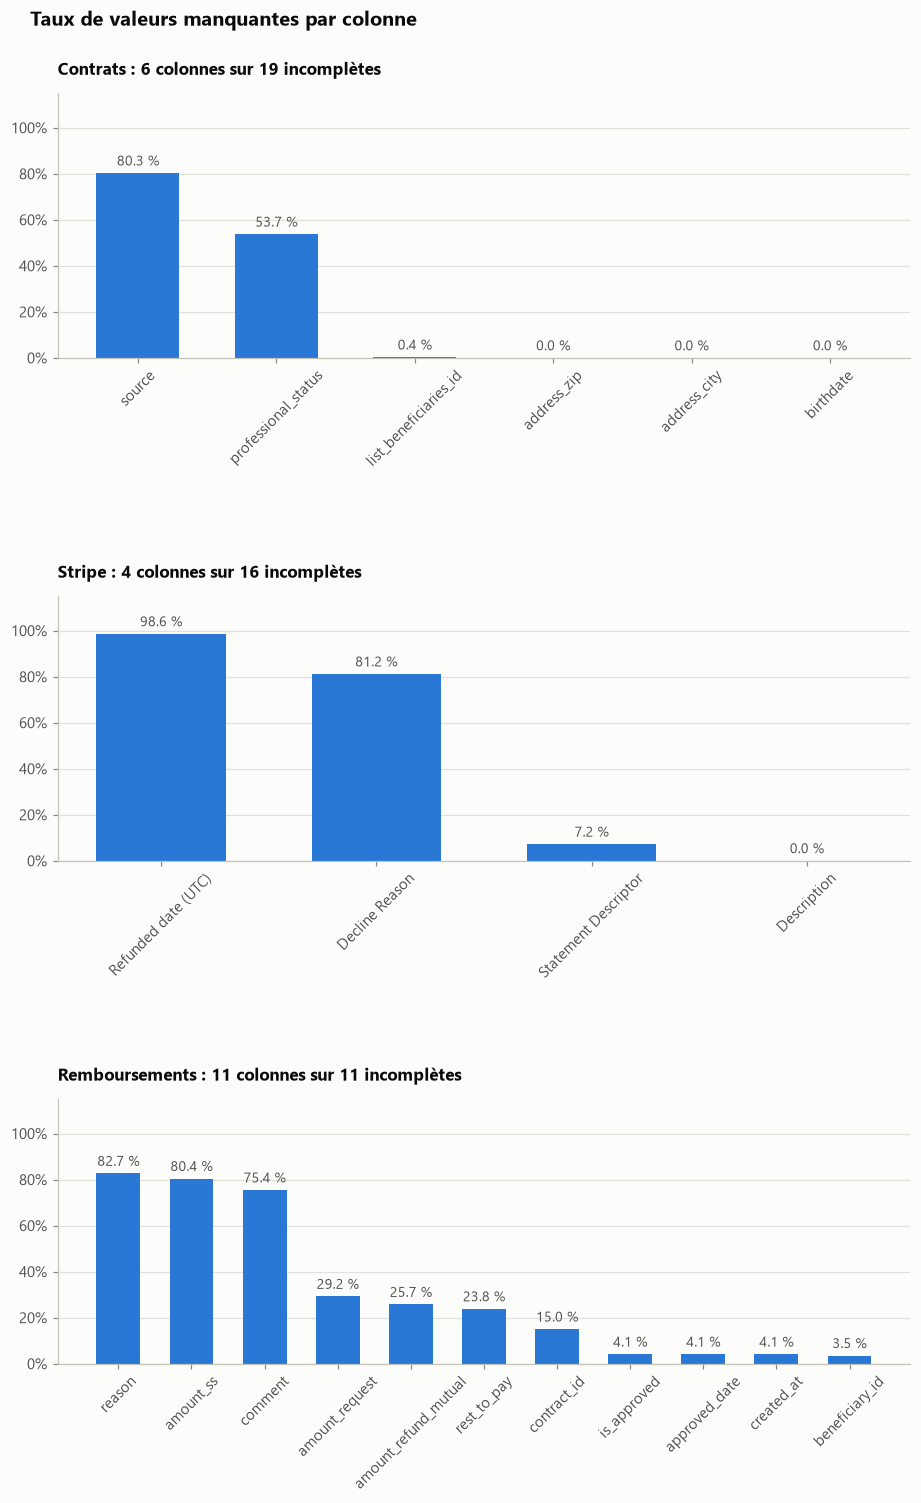

In [21]:
tables = {"Contrats": contrats_brut, "Stripe": stripe_brut, "Remboursements": remb_brut}
fig, axes = plt.subplots(3, 1, figsize=(10, 15), gridspec_kw={"hspace": 0.9})
for ax, (nom, df) in zip(axes, tables.items()):
    taux = df.isna().mean()
    taux = taux[taux > 0].sort_values(ascending=False)
    ax.bar(taux.index, taux.values, width=0.6, color=PALETTE[0])
    etiqueter_barres(ax, taux.values * 100, fmt="{:.1f} %", horizontal=False)
    ax.set_ylim(0, 1.15)
    format_pct(ax, "y")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{nom} : {len(taux)} colonnes sur {df.shape[1]} incomplètes", fontsize=11)
fig.suptitle("Taux de valeurs manquantes par colonne", x=0.1, ha="left", fontsize=13, fontweight="bold", y=0.93)
sauver(fig, "p1_valeurs_manquantes")
plt.show()

## <u>3. Recensement des anomalies</u>

Chaque anomalie est consignée dans un registre avec un code, la ou les tables concernées, sa famille, sa gravité, son volume et le traitement retenu.

| Gravité | Définition |
|---|---|
| **Critique** | fausse des jointures ou des montants financiers |
| **Majeure** | fausse une statistique demandée ou un indicateur métier |
| **Mineure** | format ou libellé, corrigeable sans perte d'information |

Codes : `X` relations entre tables, `C` Contrats, `S` Stripe, `R` Remboursements, `P` Produits.

In [22]:
registre = []

def noter(code, tables, famille, gravite, description, n, base, traitement, montant=np.nan):
    registre.append({
        "code": code, "tables": tables, "famille": famille, "gravité": gravite,
        "description": description, "lignes": int(n), "base": int(base),
        "part": n / base if base else np.nan, "montant (€)": montant, "traitement": traitement,
    })
    texte = f"[{code}] {description} : {nb(n)} / {nb(base)} ({n / base:.1%})"
    if not np.isnan(montant):
        texte += f" | {nb(montant)} €"
    print(texte)

### 3.1 Formats et types

 Il faut typer correctement les colonnes. 

- **Stripe** : les dates sont stockées en *numéro de série Excel* (nombre de jours depuis le 30/12/1899), lues par pandas comme des durées (`45953 days 23:34:05`). Les montants sont du texte avec une virgule décimale (`"35,23"`).
- **Remboursements** : trois colonnes de montants sont du texte, polluées par des identifiants et des motifs de refus (voir 3.2).
- **Contrats** : `created_at` est un texte avec fuseau horaire, `address_zip` est un nombre décimal qui perd le zéro initial des codes postaux (`1000.0` au lieu de `01000`).

In [23]:
ORIGINE_EXCEL = pd.Timestamp("1899-12-30")

def en_nombre(serie):

    # "35,23" -> 35.23 ; toute valeur non numérique devient NaN

    texte = serie.astype("string").str.strip().str.replace(",", ".", regex=False)
    return pd.to_numeric(texte, errors="coerce")

# Stripe typé 

stripe_t = pd.DataFrame({
    "contract_id": stripe_brut["Contract_id"],
    "product_id": stripe_brut["product_id"],
    "created_at": ORIGINE_EXCEL + stripe_brut["Created date (UTC) Stripe"],
    "amount": en_nombre(stripe_brut["Amount"]),
    "amount_refunded": en_nombre(stripe_brut["Amount Refunded"]),
    "converted_amount": en_nombre(stripe_brut["Converted Amount"]),
    "refunded_at": ORIGINE_EXCEL + stripe_brut["Refunded date (UTC)"],
    "status": stripe_brut["Status"],
    "captured": stripe_brut["Captured"],
    "decline_reason": stripe_brut["Decline Reason"],
    "description": stripe_brut["Description"],
    "seller_message": stripe_brut["Seller Message"],
})

# Contrats typé

contrats_t = contrats_brut.rename(columns={
    "Contrat_id": "contract_id", "Closed_Date": "closed_date", "Status_contrat": "status_contrat"
}).copy()
contrats_t["created_at"] = (pd.to_datetime(contrats_brut["created_at"], format="ISO8601", utc=True)
                            .dt.tz_convert("Europe/Paris").dt.tz_localize(None))

# Remboursements typé

remb_t = remb_brut.copy()
COLS_MONTANTS = ["amount_ss", "rest_to_pay", "amount_request"]
for col in COLS_MONTANTS:
    remb_t[col] = en_nombre(remb_brut[col])

print("Stripe : dates de", stripe_t.created_at.min(), "à", stripe_t.created_at.max())
print("Stripe : montants non convertibles :", stripe_t.amount.isna().sum())

Stripe : dates de 2021-04-22 19:19:21 à 2026-10-05 21:51:47
Stripe : montants non convertibles : 0


Enregistrement des anomalies de format (S1, S2, R5, C6)

In [24]:
noter("S1", "Stripe", "Format", "Mineure", "Dates stockées en numéro de série Excel",
      len(stripe_brut), len(stripe_brut), "Conversion en datetime (origine 30/12/1899)")
noter("S2", "Stripe", "Format", "Mineure", "Montants stockés en texte avec virgule décimale",
      len(stripe_brut), len(stripe_brut), "Conversion en nombre décimal")

texte_non_numerique = pd.concat(
    [remb_brut[c].notna() & remb_t[c].isna() for c in COLS_MONTANTS], axis=1).any(axis=1)
noter("R5", "Remboursements", "Format", "Mineure",
      "Montants en texte contenant des identifiants ou des motifs de refus",
      texte_non_numerique.sum(), len(remb_brut), "Conversion en nombre, valeurs non numériques mises à vide")

zip_ = contrats_brut["address_zip"]
noter("C6", "Contrats", "Format", "Mineure", "Code postal numérique : zéro initial perdu ou code invalide",
      ((zip_ < 10000) | zip_.isna()).sum(), len(contrats_brut), "Texte sur 5 caractères, codes < 1000 mis à vide")
print("dont codes invalides (< 1000) :", (zip_ < 1000).sum(), "| manquants :", zip_.isna().sum())

[S1] Dates stockées en numéro de série Excel : 166 373 / 166 373 (100.0%)
[S2] Montants stockés en texte avec virgule décimale : 166 373 / 166 373 (100.0%)
[R5] Montants en texte contenant des identifiants ou des motifs de refus : 742 / 55 522 (1.3%)
[C6] Code postal numérique : zéro initial perdu ou code invalide : 672 / 12 484 (5.4%)
dont codes invalides (< 1000) : 1 | manquants : 3


### 3.2 Structure de la table Remboursements

La table contient des lignes **entièrement vides** et des **lignes fragmentées** : sans date ni statut, avec des identifiants et des motifs de refus décalés dans des colonnes qui ne leur correspondent pas (un UUID dans `comment` ou `rest_to_pay`, un motif comme `PHARMACIE NON PRIS EN CHARGE` dans `contract_id`). C'est la signature d'un export corrompu. Ces lignes ne sont pas réparables de façon fiable.

Des lignes entièrement vides 

In [25]:
vide = remb_brut.isna().all(axis=1)
vide.sum()

np.int64(1470)

In [26]:
remb_brut[vide].head()

,created_at,approved_date,beneficiary_id,is_approved,comment,amount_ss,rest_to_pay,amount_request,contract_id,amount_refund_mutual,reason
241,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
310,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
468,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
488,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
660,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Des lignes fragmentées, sans statut

In [27]:
fragment = ~vide & remb_brut["is_approved"].isna()
fragment.sum()

np.int64(831)

In [28]:
remb_brut[fragment].head()

,created_at,approved_date,beneficiary_id,is_approved,comment,amount_ss,rest_to_pay,amount_request,contract_id,amount_refund_mutual,reason
242,NaT,NaT,NaN,NaN,b7547825-8ce3-4c3a-b2b7-35cd49eaafaf,NaN,ef856fc1-d78f-4e7d-8b62-6f3b0b459008,NaN,PHARMACIE NON PRIS EN CHARGE,NaN,NaN
311,NaT,NaT,718f4994-5621-47d9-b3c4-e14a8dfd8051,NaN,NaN,b98b5c19-b7b5-4290-847a-44be81f52e5f,NaN,NaN,NaN,NaN,NaN
469,NaT,NaT,NaN,NaN,NaN,NaN,af748a39-91be-4191-83d4-925652ff449c,NaN,PHARMACIE NON PRIS EN CHARGE,NaN,NaN
489,NaT,NaT,NaN,NaN,NaN,NaN,b8215c0f-eff0-4a41-ad7f-b72b32f1056a,NaN,PHARMACIE NON PRIS EN CHARGE,NaN,NaN
606,NaT,NaT,2f990cc7-f885-4108-b064-a7dbbab9620f,NaN,e4138af7-c7e3-46ec-878a-75ca9eaa64a8,NaN,NaN,NOT_COVERED,NaN,NaN,NaN


In [29]:
fragment = ~vide & remb_brut["is_approved"].isna()
remb_brut.loc[fragment].head()

,created_at,approved_date,beneficiary_id,is_approved,comment,amount_ss,rest_to_pay,amount_request,contract_id,amount_refund_mutual,reason
242,NaT,NaT,NaN,NaN,b7547825-8ce3-4c3a-b2b7-35cd49eaafaf,NaN,ef856fc1-d78f-4e7d-8b62-6f3b0b459008,NaN,PHARMACIE NON PRIS EN CHARGE,NaN,NaN
311,NaT,NaT,718f4994-5621-47d9-b3c4-e14a8dfd8051,NaN,NaN,b98b5c19-b7b5-4290-847a-44be81f52e5f,NaN,NaN,NaN,NaN,NaN
469,NaT,NaT,NaN,NaN,NaN,NaN,af748a39-91be-4191-83d4-925652ff449c,NaN,PHARMACIE NON PRIS EN CHARGE,NaN,NaN
489,NaT,NaT,NaN,NaN,NaN,NaN,b8215c0f-eff0-4a41-ad7f-b72b32f1056a,NaN,PHARMACIE NON PRIS EN CHARGE,NaN,NaN
606,NaT,NaT,2f990cc7-f885-4108-b064-a7dbbab9620f,NaN,e4138af7-c7e3-46ec-878a-75ca9eaa64a8,NaN,NaN,NOT_COVERED,NaN,NaN,NaN


Des identifiants (UUID) dans des colonnes de texte ou de montant

In [30]:
for col in ["comment", "amount_ss", "rest_to_pay"]:
    print(col, ":", remb_brut[col].astype("string").str.fullmatch(UUID).sum(), "cellules contenant un UUID")

comment : 455 cellules contenant un UUID
amount_ss : 210 cellules contenant un UUID
rest_to_pay : 348 cellules contenant un UUID


Enregistrement des anomalies R1 et R2, et sélection des lignes valides

In [31]:
noter("R1", "Remboursements", "Structure", "Majeure", "Lignes entièrement vides",
      vide.sum(), len(remb_brut), "Suppression")
noter("R2", "Remboursements", "Structure", "Majeure",
      "Lignes fragmentées (export corrompu, colonnes décalées, sans date ni statut)",
      fragment.sum(), len(remb_brut), "Suppression (non réparable de façon fiable)")

remb_valides = remb_t.loc[~vide & ~fragment].copy()

[R1] Lignes entièrement vides : 1 470 / 55 522 (2.6%)
[R2] Lignes fragmentées (export corrompu, colonnes décalées, sans date ni statut) : 831 / 55 522 (1.5%)


Contrôle de doublons et dates aberrantes après retrait des lignes inexploitables

In [32]:
annee = remb_t["created_at"].dt.year
print("Doublons exacts (lignes vides exclues) :", remb_t.loc[~vide].duplicated().sum(),
      "| parmi les lignes valides :", remb_valides.duplicated().sum())
print("Dates de création avant 2020 :", (annee < 2020).sum(), "| dont dans des fragments :", ((annee < 2020) & fragment).sum())
print("Dates postérieures à l'extraction :", (remb_t["created_at"] > DATE_EXTRACTION + pd.Timedelta(days=1)).sum(),
      "| parmi les lignes valides :", (remb_valides["created_at"] > DATE_EXTRACTION + pd.Timedelta(days=1)).sum())

Doublons exacts (lignes vides exclues) : 377 | parmi les lignes valides : 0
Dates de création avant 2020 : 2 | dont dans des fragments : 2
Dates postérieures à l'extraction : 1 | parmi les lignes valides : 0


Retrait des lignes vides et fragmentées (R1, R2), puis contrôle des doublons et des dates

In [33]:
noter("R1", "Remboursements", "Structure", "Majeure", "Lignes entièrement vides",
      vide.sum(), len(remb_brut), "Suppression")
noter("R2", "Remboursements", "Structure", "Majeure",
      "Lignes fragmentées (export corrompu, colonnes décalées, sans date ni statut)",
      fragment.sum(), len(remb_brut), "Suppression (non réparable de façon fiable)")

remb_valides = remb_t.loc[~vide & ~fragment].copy()

# Doublons exacts et dates aberrantes : présents dans les fragments, plus aucun une fois ceux-ci écartés

annee = remb_t["created_at"].dt.year
print("Doublons exacts (lignes vides exclues) :", remb_t.loc[~vide].duplicated().sum(),
      "| parmi les lignes valides :", remb_valides.duplicated().sum())
print("Dates de création avant 2020 :", (annee < 2020).sum(), "| dont dans des fragments :", ((annee < 2020) & fragment).sum())
print("Dates postérieures à l'extraction :", (remb_t["created_at"] > DATE_EXTRACTION + pd.Timedelta(days=1)).sum(),
      "| parmi les lignes valides :", (remb_valides["created_at"] > DATE_EXTRACTION + pd.Timedelta(days=1)).sum())

[R1] Lignes entièrement vides : 1 470 / 55 522 (2.6%)
[R2] Lignes fragmentées (export corrompu, colonnes décalées, sans date ni statut) : 831 / 55 522 (1.5%)
Doublons exacts (lignes vides exclues) : 377 | parmi les lignes valides : 0
Dates de création avant 2020 : 2 | dont dans des fragments : 2
Dates postérieures à l'extraction : 1 | parmi les lignes valides : 0


##### **Lecture des résultats** 

On constate enfin que 2 301 lignes sur 55 522 (4,1 %) sont inexploitables, 1 470 vides et 831 fragments. Les doublons exacts et les dates aberrantes se trouvent **tous** dans ces fragments. Une fois ces derniers écartés, il ne reste ni doublon ni date hors période. On travaille désormais sur les 53 221 demandes valides.

### 3.3 Une ligne par contrat ?

*Contrats* devrait contenir une ligne par contrat. Mais, certains `Contrat_id` apparaissent sur plusieurs lignes, avec le même `user_id`, la même liste de bénéficiaires, les mêmes dates et le même prix, mais un `beneficiary_id` et un `created_at` différents. Le souscripteur a été créé plusieurs fois. Cela fait que **toute jointure Stripe ou Remboursements sur Contrats duplique les paiements et les remboursements**.

In [34]:
lignes_par_contrat = contrats_t["contract_id"].value_counts()
ids_dupliques = lignes_par_contrat[lignes_par_contrat > 1]
groupes = contrats_t[contrats_t["contract_id"].isin(ids_dupliques.index)]

colonnes_variables = (groupes.groupby("contract_id").nunique() > 1).mean().sort_values(ascending=False)
print("Part des contrats dupliqués où la colonne varie entre les lignes :")
print(colonnes_variables[colonnes_variables > 0].map("{:.0%}".format).to_string())

# Effet d'une jointure naïve Stripe -> Contrats

surplus = (lignes_par_contrat - 1).reindex(stripe_t["contract_id"]).fillna(0).to_numpy()
paye = (stripe_t["status"] == "Paid").to_numpy()
montant_double = float((stripe_t["amount"].to_numpy() * surplus)[paye].sum())
surplus_remb = (lignes_par_contrat - 1).reindex(remb_valides["contract_id"]).fillna(0).to_numpy()
remb_double = float(np.nansum(remb_valides["amount_refund_mutual"].to_numpy() * surplus_remb))
print(f"\nJointure naïve : +{nb(surplus.sum())} lignes Stripe, {nb(montant_double)} € d'encaissements comptés en double")
print(f"Jointure naïve : +{nb(surplus_remb.sum())} lignes Remboursements, {nb(remb_double)} € de remboursements comptés en double")

Part des contrats dupliqués où la colonne varie entre les lignes :
beneficiary_id                 100%
created_at                     100%
professional_status             15%
gender                           6%
birthdate                        4%
beneficiary_individual_type      0%

Jointure naïve : +3 328 lignes Stripe, 121 876 € d'encaissements comptés en double
Jointure naïve : +425 lignes Remboursements, 13 881 € de remboursements comptés en double


Enregistrement des anomalies de clé (X1, X2)

In [35]:
noter("X1", "Contrats ↔ Stripe, Remboursements", "Clé", "Critique",
      "Contrat_id non unique",
      len(groupes) - len(ids_dupliques), len(contrats_t),
      "Une ligne par contrat (souscripteur présent dans la liste des bénéficiaires, sinon le plus récent) ; autres beneficiary_id gardés dans une table pont",
      montant=montant_double)
noter("X2", "Stripe, Remboursements", "Clé", "Majeure",
      "Aucun identifiant de ligne",
      len(stripe_t) + len(remb_brut), len(stripe_t) + len(remb_brut),
      "Création d'un identifiant technique après nettoyage")

[X1] Contrat_id non unique : 268 / 12 484 (2.1%) | 121 876 €
[X2] Aucun identifiant de ligne : 221 895 / 221 895 (100.0%)


####  **Lecture des résultats**
On constate que 248 contrats sont répartis sur 516 lignes, soit 268 lignes en trop (2,1 %). Seuls `beneficiary_id` et `created_at` changent systématiquement ; le genre, la date de naissance ou le statut professionnel ne changent que dans 4 à 15 % des groupes, ce qui confirme une **double saisie du même souscripteur**. Une jointure naïve ajouterait 3 328 lignes de paiements et compterait **121 876 € d'encaissements en double** : c'est l'anomalie la plus dangereuse pour les statistiques de la partie 2, d'où un dédoublonnage strict avant toute jointure.

### 3.4 Contrôle des liens entre tables 

Les contrôles relationnels s'expriment en SQL. Les tables typées sont chargées dans une base SQLite en mémoire. La table `beneficiaires` déplie `list_beneficiaries_id` : elle relie chaque contrat à tous ses bénéficiaires (souscripteur, conjoint, enfants), ce qui permet de vérifier les bénéficiaires cités dans les remboursements.

In [36]:
con = sqlite3.connect(":memory:")

def vers_sql(df, nom):
    d = df.copy()
    for col in d.columns:
        if pd.api.types.is_datetime64_any_dtype(d[col]):
            d[col] = d[col].dt.strftime("%Y-%m-%d %H:%M:%S")
        elif pd.api.types.is_bool_dtype(d[col]):
            d[col] = d[col].astype(int)
    d.to_sql(nom, con, index=False)

def sql(requete):
    return pd.read_sql_query(requete, con)

liste_benef = contrats_t["list_beneficiaries_id"].fillna("").str.findall(UUID)
beneficiaires_t = pd.concat([
    contrats_t[["contract_id", "beneficiary_id"]],
    pd.DataFrame({"contract_id": contrats_t["contract_id"], "beneficiary_id": liste_benef}).explode("beneficiary_id"),
]).dropna().drop_duplicates()

vers_sql(contrats_t[["contract_id", "user_id", "beneficiary_id", "product_id", "start_date",
                     "signature_date", "closed_date", "status_contrat"]], "contrats")
vers_sql(stripe_t[["contract_id", "product_id", "created_at", "amount", "amount_refunded", "status"]], "stripe")
vers_sql(remb_valides[["created_at", "beneficiary_id", "contract_id", "is_approved", "amount_refund_mutual"]],
         "remboursements")
vers_sql(beneficiaires_t, "beneficiaires")
vers_sql(produits_brut.rename(columns={"id": "product_id"}), "produits")
con.executescript('''
    CREATE INDEX ix_c ON contrats(contract_id);
    CREATE INDEX ix_s ON stripe(contract_id);
    CREATE INDEX ix_r ON remboursements(contract_id);
    CREATE INDEX ix_b ON beneficiaires(contract_id, beneficiary_id);
    CREATE INDEX ix_b2 ON beneficiaires(beneficiary_id);
    -- une ligne par contrat (les lignes dupliquées partagent toutes les dates et le statut)
    CREATE VIEW contrats_u AS
        SELECT DISTINCT contract_id, product_id, start_date, signature_date, closed_date, status_contrat FROM contrats;
''')
print({t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ["contrats", "stripe", "remboursements", "beneficiaires", "produits"]})

{'contrats': 12484, 'stripe': 166373, 'remboursements': 53221, 'beneficiaires': 15209, 'produits': 58}


Paiements Stripe rattachés à un contrat inconnu

In [37]:
orphelins_stripe = sql('''
    SELECT COUNT(*) AS paiements,
           COUNT(DISTINCT s.contract_id) AS contrats,
           ROUND(SUM(CASE WHEN s.status = 'Paid' THEN s.amount - s.amount_refunded ELSE 0 END), 2) AS encaisse_net
    FROM stripe s
    WHERE NOT EXISTS (SELECT 1 FROM contrats c WHERE c.contract_id = s.contract_id)
''')
orphelins_stripe

,paiements,contrats,encaisse_net
0,793,74,43 795.59


Enregistrement de l'anomalie X3 et contrôle des références produit

In [38]:
noter("X3", "Stripe → Contrats", "Intégrité référentielle", "Critique",
      "Paiements Stripe rattachés à un contrat absent de Contrats",
      orphelins_stripe.at[0, "paiements"], len(stripe_t),
      "Signalement (flag_contrat_inconnu), exclus des analyses croisées",
      montant=orphelins_stripe.at[0, "encaisse_net"])
print(f"soit {orphelins_stripe.at[0, 'contrats']} contrats distincts")

controle_produits = sql('''
    SELECT SUM(NOT EXISTS (SELECT 1 FROM produits p WHERE p.product_id = s.product_id)) AS produit_inconnu_stripe,
           SUM(EXISTS (SELECT 1 FROM contrats_u c WHERE c.contract_id = s.contract_id AND c.product_id <> s.product_id)) AS produit_different_du_contrat,
           (SELECT COUNT(*) FROM contrats c WHERE NOT EXISTS (SELECT 1 FROM produits p WHERE p.product_id = c.product_id)) AS produit_inconnu_contrats
    FROM stripe s
''')
controle_produits

[X3] Paiements Stripe rattachés à un contrat absent de Contrats : 793 / 166 373 (0.5%) | 43 796 €
soit 74 contrats distincts


,produit_inconnu_stripe,produit_different_du_contrat,produit_inconnu_contrats
0,0,0,0


 Contrats sans paiement Stripe ou jamais encaissés

In [39]:
couverture_stripe = sql('''
    WITH agg AS (
        SELECT contract_id, COUNT(*) AS nb, SUM(status = 'Paid') AS nb_paye
        FROM stripe GROUP BY contract_id
    )
    SELECT c.status_contrat,
           COUNT(*) AS contrats,
           SUM(agg.contract_id IS NULL) AS sans_transaction,
           SUM(agg.nb_paye = 0) AS transactions_toutes_en_echec
    FROM contrats_u c LEFT JOIN agg USING (contract_id)
    GROUP BY c.status_contrat
''')
couverture_stripe

,status_contrat,contrats,sans_transaction,transactions_toutes_en_echec
0,Contrat Fermé,6904,1107,849
1,Contrat en cours,5312,162,40


Enregistrement des anomalies X4 et X5

In [40]:
nb_contrats = contrats_t["contract_id"].nunique()
noter("X4", "Contrats → Stripe", "Intégrité référentielle", "Majeure",
      "Contrats sans aucune transaction Stripe",
      couverture_stripe["sans_transaction"].sum(), nb_contrats,
      "Signalement (flag_sans_transaction)")
noter("X5", "Contrats → Stripe", "Intégrité référentielle", "Critique",
      "Contrats dont toutes les transactions Stripe ont échoué (aucune cotisation encaissée)",
      couverture_stripe["transactions_toutes_en_echec"].sum(), nb_contrats,
      "Signalement (flag_jamais_encaisse)")



[X4] Contrats sans aucune transaction Stripe : 1 269 / 12 216 (10.4%)
[X5] Contrats dont toutes les transactions Stripe ont échoué (aucune cotisation encaissée) : 889 / 12 216 (7.3%)


Pistes d'explication des contrats sans transaction

In [41]:
cu = contrats_t.drop_duplicates("contract_id").set_index("contract_id")
sans_tx = cu[~cu.index.isin(stripe_t["contract_id"])]
pistes = pd.Series({
    "fermé avant sa date d'effet": (sans_tx["closed_date"] < sans_tx["start_date"]).sum(),
    "date d'effet future": (sans_tx["start_date"] > DATE_EXTRACTION).sum(),
    "signé il y a moins de 30 jours": (sans_tx["signature_date"] > DATE_EXTRACTION - pd.Timedelta(days=30)).sum(),
    "issu de la reprise du 03/06/2025": (sans_tx["created_at"].dt.normalize() == DATE_MIGRATION).sum(),
}, name="contrats (non exclusifs)")
print(f"{len(sans_tx)} contrats sans transaction, pistes d'explication :")
pistes.to_frame()

1269 contrats sans transaction, pistes d'explication :


,contrats (non exclusifs)
fermé avant sa date d'effet,195
date d'effet future,84
signé il y a moins de 30 jours,206
issu de la reprise du 03/06/2025,517


Remboursements rattachés à un contrat ou à un bénéficiaire inconnu

In [42]:
integrite_remb = sql('''
    SELECT COUNT(*) AS lignes,
           SUM(r.contract_id IS NULL) AS contrat_absent,
           SUM(r.contract_id IS NOT NULL
               AND NOT EXISTS (SELECT 1 FROM contrats c WHERE c.contract_id = r.contract_id)) AS contrat_inconnu,
           SUM(r.beneficiary_id IS NOT NULL
               AND NOT EXISTS (SELECT 1 FROM beneficiaires b WHERE b.beneficiary_id = r.beneficiary_id)) AS beneficiaire_inconnu,
           SUM(r.contract_id IS NOT NULL AND r.beneficiary_id IS NOT NULL
               AND EXISTS (SELECT 1 FROM contrats c WHERE c.contract_id = r.contract_id)
               AND EXISTS (SELECT 1 FROM beneficiaires b WHERE b.beneficiary_id = r.beneficiary_id)
               AND NOT EXISTS (SELECT 1 FROM beneficiaires b
                               WHERE b.contract_id = r.contract_id AND b.beneficiary_id = r.beneficiary_id)) AS beneficiaire_hors_contrat
    FROM remboursements r
''')
integrite_remb

,lignes,contrat_absent,contrat_inconnu,beneficiaire_inconnu,beneficiaire_hors_contrat
0,53221,6391,8,286,16


Enregistrement des anomalies de rattachement des remboursements (X6 à X9)

In [43]:
n_remb = len(remb_valides)
absent_par_statut = remb_valides.loc[remb_valides["contract_id"].isna(), "is_approved"].value_counts().rename({0.0: "refusés", 1.0: "approuvés"})
print("Contrat absent, par statut :", absent_par_statut.to_dict())
noter("X6", "Remboursements → Contrats", "Intégrité référentielle", "Majeure",
      "Remboursements sans contract_id", integrite_remb.at[0, "contrat_absent"], n_remb,
      "Contrat déduit du bénéficiaire quand il n'appartient qu'à un seul contrat, sinon flag")
noter("X7", "Remboursements → Contrats", "Intégrité référentielle", "Majeure",
      "Remboursements rattachés à un contrat absent de Contrats", integrite_remb.at[0, "contrat_inconnu"], n_remb,
      "Même traitement que X6")
noter("X8", "Remboursements → Contrats", "Intégrité référentielle", "Majeure",
      "Bénéficiaire inconnu (absent de tous les contrats et listes de bénéficiaires)",
      integrite_remb.at[0, "beneficiaire_inconnu"], n_remb, "Signalement (flag_beneficiaire_inconnu)")
noter("X9", "Remboursements → Contrats", "Intégrité référentielle", "Majeure",
      "Bénéficiaire connu mais non rattaché au contrat indiqué",
      integrite_remb.at[0, "beneficiaire_hors_contrat"], n_remb, "Signalement (flag_beneficiaire_hors_contrat)")

Contrat absent, par statut : {'refusés': 6014, 'approuvés': 377}
[X6] Remboursements sans contract_id : 6 391 / 53 221 (12.0%)
[X7] Remboursements rattachés à un contrat absent de Contrats : 8 / 53 221 (0.0%)
[X8] Bénéficiaire inconnu (absent de tous les contrats et listes de bénéficiaires) : 286 / 53 221 (0.5%)
[X9] Bénéficiaire connu mais non rattaché au contrat indiqué : 16 / 53 221 (0.0%)


Couverture des liens entre tables : tableau récapitulatif

In [44]:
couverture = pd.DataFrame({
    "Stripe → Contrats\n(paiements)": [len(stripe_t) - orphelins_stripe.at[0, "paiements"], 0, orphelins_stripe.at[0, "paiements"]],
    "Contrats → Stripe\n(contrats)": [nb_contrats - couverture_stripe["sans_transaction"].sum(), couverture_stripe["sans_transaction"].sum(), 0],
    "Remboursements → Contrats\n(demandes)": [n_remb - integrite_remb.at[0, "contrat_absent"] - integrite_remb.at[0, "contrat_inconnu"],
                                             integrite_remb.at[0, "contrat_absent"], integrite_remb.at[0, "contrat_inconnu"]],
    "Remboursements → Bénéficiaires\n(demandes)": [n_remb - integrite_remb.at[0, "beneficiaire_inconnu"] - integrite_remb.at[0, "beneficiaire_hors_contrat"],
                                                  integrite_remb.at[0, "beneficiaire_hors_contrat"], integrite_remb.at[0, "beneficiaire_inconnu"]],
}, index=["Rattaché", "Absent ou hors contrat", "Inconnu"]).T
parts = couverture.div(couverture.sum(axis=1), axis=0)
couverture.assign(**{"part en anomalie": 1 - parts["Rattaché"]}).style.format({"part en anomalie": "{:.1%}"}, thousands=" ")

,Rattaché,Absent ou hors contrat,Inconnu,part en anomalie
Stripe → Contrats (paiements),165 580,0,793,0.5%
Contrats → Stripe (contrats),10 947,1 269,0,10.4%
Remboursements → Contrats (demandes),46 822,6 391,8,12.0%
Remboursements → Bénéficiaires (demandes),52 919,16,286,0.6%


Couverture des liens entre tables : part des lignes non rattachées

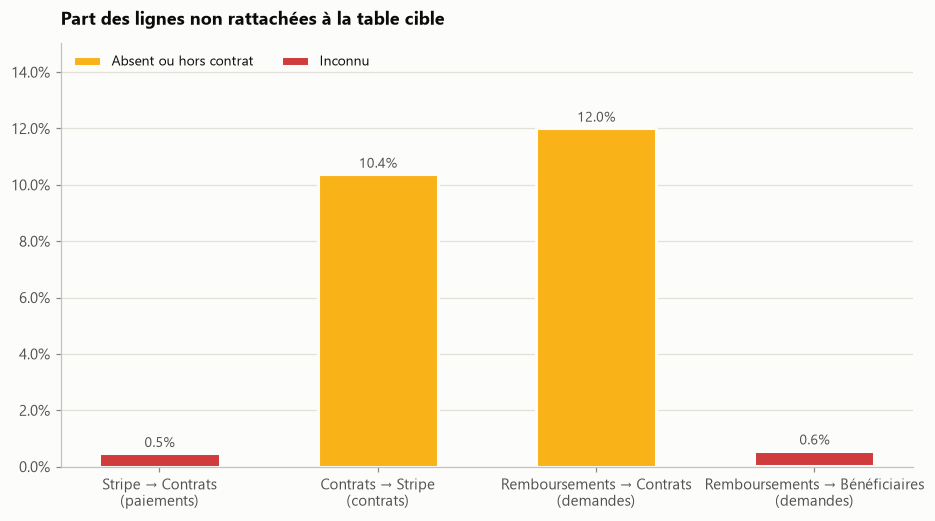

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
bas = np.zeros(len(parts))
for col, couleur in zip(["Absent ou hors contrat", "Inconnu"], [STATUT["mineure"], STATUT["critique"]]):
    ax.bar(parts.index, parts[col], bottom=bas, width=0.55, color=couleur, label=col,
           edgecolor=ENCRE["fond"], linewidth=2)
    bas += parts[col].to_numpy()
for i, total in enumerate(bas):
    ax.annotate(f"{total:.1%}", (i, total), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=ENCRE["secondaire"])
ax.set_ylim(0, bas.max() * 1.25)
format_pct(ax, "y", 1)
ax.grid(axis="x", visible=False)
ax.legend(ncol=2, loc="upper left")
ax.set_title("Part des lignes non rattachées à la table cible")
sauver(fig, "p1_couverture_referentielle")
plt.show()

##### **Lecture des résultats**

- **Stripe → Contrats** : 793 paiements (0,5 %) citent 74 contrats introuvables dans la table Contrats, pour **43 796 € encaissés**. Ces contrats ont sans doute été supprimés, ou non exportés.
- **Contrats → Stripe** : 1 269 contrats (10,4 %) n'ont aucun paiement, souvent pour une raison normale : annulés avant leur début, pas encore commencés, signés récemment, ou payés dans l'ancien système avant la reprise. Par ailleurs, **889 contrats (7,3 %) n'ont que des paiements échoués**, et presque tous sont fermés : probablement des résiliations pour impayé.
- **Remboursements → Contrats** : 6 391 demandes (12 %) n'ont pas de numéro de contrat. Ce sont surtout des refus, mais **377 ont été remboursées**.
- **Remboursements → Bénéficiaires** : 286 demandes citent un bénéficiaire inconnu, et 16 un bénéficiaire qui n'appartient pas au contrat indiqué.
- **Produits** : aucune anomalie.

### 3.5 Cohérence temporelle entre tables (SQL)

Ici, il est question de confronter les dates des paiements et des remboursements à la vie du contrat (signature, début, clôture).

In [46]:
temporel_stripe = sql('''
    SELECT
      SUM(s.status = 'Paid' AND julianday(s.created_at) < julianday(c.signature_date) - 31) AS paye_avant_signature,
      SUM(s.status = 'Paid' AND julianday(s.created_at) < julianday(c.start_date) - 31) AS paye_avant_debut,
      SUM(s.status = 'Paid' AND c.status_contrat = 'Contrat Fermé'
          AND julianday(s.created_at) > julianday(c.closed_date) + 31) AS paye_apres_cloture,
      COUNT(DISTINCT CASE WHEN s.status = 'Paid' AND c.status_contrat = 'Contrat Fermé'
          AND julianday(s.created_at) > julianday(c.closed_date) + 31 THEN s.contract_id END) AS contrats_apres_cloture,
      ROUND(SUM(CASE WHEN s.status = 'Paid' AND c.status_contrat = 'Contrat Fermé'
          AND julianday(s.created_at) > julianday(c.closed_date) + 31 THEN s.amount - s.amount_refunded END), 2) AS montant_apres_cloture,
      SUM(s.status = 'Paid') AS paiements_encaisses
    FROM stripe s JOIN contrats_u c USING (contract_id)
''')
temporel_stripe

,paye_avant_signature,paye_avant_debut,paye_apres_cloture,contrats_apres_cloture,montant_apres_cloture,paiements_encaisses
0,11738,1189,1446,294,95 109.79,132108


Enregistrement des anomalies de dates des paiements (X10, X11)

In [47]:
base_paye = temporel_stripe.at[0, "paiements_encaisses"]
noter("X10", "Stripe ↔ Contrats", "Cohérence temporelle", "Majeure",
      "Paiement encaissé plus de 31 jours avant la signature du contrat",
      temporel_stripe.at[0, "paye_avant_signature"], base_paye,
      "Signalement (flag_avant_signature) : la date de signature n'est pas fiable (voir C3, C5)")
noter("X11", "Stripe ↔ Contrats", "Cohérence temporelle", "Critique",
      "Paiement encaissé plus de 31 jours après la clôture du contrat",
      temporel_stripe.at[0, "paye_apres_cloture"], base_paye,
      "Signalement (flag_apres_cloture) : encaissement indu ou date de clôture erronée",
      montant=temporel_stripe.at[0, "montant_apres_cloture"])
print(f"soit {temporel_stripe.at[0, 'contrats_apres_cloture']} contrats ; encaissés > 31 j avant la date d'effet : {temporel_stripe.at[0, 'paye_avant_debut']}")

[X10] Paiement encaissé plus de 31 jours avant la signature du contrat : 11 738 / 132 108 (8.9%)
[X11] Paiement encaissé plus de 31 jours après la clôture du contrat : 1 446 / 132 108 (1.1%) | 95 110 €
soit 294 contrats ; encaissés > 31 j avant la date d'effet : 1189


Délai entre la clôture du contrat et les paiements encaissés après

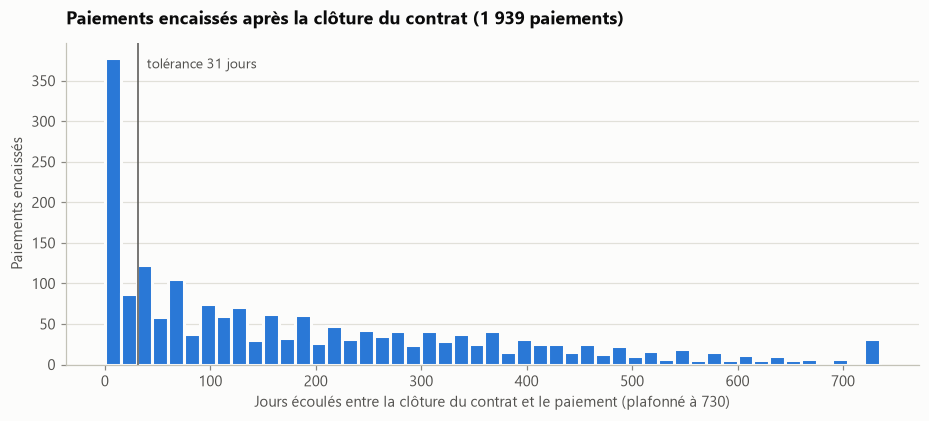

In [48]:
apres = sql('''
    SELECT julianday(s.created_at) - julianday(c.closed_date) AS jours
    FROM stripe s JOIN contrats_u c USING (contract_id)
    WHERE s.status = 'Paid' AND c.status_contrat = 'Contrat Fermé' AND s.created_at > c.closed_date
''')["jours"]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(apres.clip(upper=730), bins=np.arange(0, 745, 15), color=PALETTE[0], edgecolor=ENCRE["fond"], linewidth=2)
ax.axvline(31, color=ENCRE["secondaire"], linewidth=1)
ax.annotate("tolérance 31 jours", (31, ax.get_ylim()[1] * 0.92), xytext=(6, 0), textcoords="offset points",
            fontsize=9, color=ENCRE["secondaire"])
ax.set_xlabel("Jours écoulés entre la clôture du contrat et le paiement (plafonné à 730)")
ax.set_ylabel("Paiements encaissés")
ax.grid(axis="x", visible=False)
ax.set_title(f"Paiements encaissés après la clôture du contrat ({nb(len(apres))} paiements)")
sauver(fig, "p1_paiements_apres_cloture")
plt.show()

##### **Lecture des résultats** 

On constate que sur 1 939 paiements encaissés après la clôture, 1 446 le sont **plus d'un mois après** (294 contrats, **95 110 €**). La distribution s'étale sur deux ans : ce n'est pas un décalage de facturation. Soit l'abonnement Stripe n'a pas été arrêté à la résiliation (prélèvements indus, à rembourser, avec un risque de réclamation), soit la date de clôture est fausse. Dans les deux cas, c'est un sujet à remonter à la finance.

À l'inverse, 11 738 paiements (8,9 %) sont encaissés plus d'un mois **avant la signature**, mais seulement 1 189 avant la date d'effet : c'est la **date de signature** qui est fausse, pas le paiement (voir C5).

Remboursements approuvés hors période de couverture ou sans cotisation payée

In [49]:
temporel_remb = sql('''
    WITH paye AS (SELECT DISTINCT contract_id FROM stripe WHERE status = 'Paid')
    SELECT
      SUM(r.is_approved = 1) AS approuves,
      SUM(r.is_approved = 1 AND julianday(r.created_at) < julianday(c.start_date)) AS approuve_avant_debut,
      SUM(r.is_approved = 1 AND c.status_contrat = 'Contrat Fermé'
          AND julianday(r.created_at) > julianday(c.closed_date) + 90) AS approuve_90j_apres_cloture,
      SUM(r.is_approved = 1 AND r.contract_id NOT IN (SELECT contract_id FROM paye)) AS approuve_sans_cotisation,
      COUNT(DISTINCT CASE WHEN r.is_approved = 1 AND r.contract_id NOT IN (SELECT contract_id FROM paye) THEN r.contract_id END) AS contrats_sans_cotisation,
      ROUND(SUM(CASE WHEN r.is_approved = 1 AND r.contract_id NOT IN (SELECT contract_id FROM paye) THEN r.amount_refund_mutual END), 2) AS montant_sans_cotisation
    FROM remboursements r JOIN contrats_u c USING (contract_id)
''')
temporel_remb

,approuves,approuve_avant_debut,approuve_90j_apres_cloture,approuve_sans_cotisation,contrats_sans_cotisation,montant_sans_cotisation
0,41890,13,382,456,119,17 366.49


 Enregistrement des anomalies de remboursement (X12, X13, X14)

In [50]:
base_ap = temporel_remb.at[0, "approuves"]
noter("X12", "Remboursements ↔ Contrats", "Cohérence temporelle", "Majeure",
      "Remboursement approuvé avant la date d'effet du contrat",
      temporel_remb.at[0, "approuve_avant_debut"], base_ap, "Signalement (flag_avant_effet)")
noter("X13", "Remboursements ↔ Contrats", "Cohérence temporelle", "Mineure",
      "Remboursement approuvé plus de 90 jours après la clôture (à contrôler : la date de soin est inconnue)",
      temporel_remb.at[0, "approuve_90j_apres_cloture"], base_ap, "Signalement (flag_apres_cloture_90j)")
noter("X14", "Remboursements ↔ Stripe", "Cohérence métier", "Critique",
      "Remboursement approuvé sur un contrat sans aucune cotisation encaissée",
      temporel_remb.at[0, "approuve_sans_cotisation"], base_ap, "Signalement (flag_contrat_jamais_encaisse)",
      montant=temporel_remb.at[0, "montant_sans_cotisation"])
print(f"soit {temporel_remb.at[0, 'contrats_sans_cotisation']} contrats")

[X12] Remboursement approuvé avant la date d'effet du contrat : 13 / 41 890 (0.0%)
[X13] Remboursement approuvé plus de 90 jours après la clôture (à contrôler : la date de soin est inconnue) : 382 / 41 890 (0.9%)
[X14] Remboursement approuvé sur un contrat sans aucune cotisation encaissée : 456 / 41 890 (1.1%) | 17 366 €
soit 119 contrats


##### **Lecture des résultats** 

 **456 remboursements approuvés (17 366 €) concernent 119 contrats qui n'ont jamais payé une seule cotisation**. C'est le signal le plus sensible côté risque : défaut de contrôle à l'adhésion, voire fraude. 13 remboursements sont approuvés avant la date d'effet du contrat. Les 382 remboursements approuvés plus de 90 jours après la clôture ne sont pas forcément anormaux (on peut envoyer une facture tardive pour un soin réalisé pendant la couverture), mais la date de soin n'est pas disponible pour le vérifier.

### 3.6 Qualité interne de chaque table

#### Contrats

Enregistrement des anomalies de date de clôture (C1, C2)

In [51]:
cu = contrats_t.drop_duplicates("contract_id")
en_cours = cu["status_contrat"] == "Contrat en cours"
ferme = ~en_cours

noter("C1", "Contrats", "Cohérence", "Majeure",
      "Date de clôture renseignée pour un contrat en cours",
      (en_cours & cu["closed_date"].notna()).sum(), en_cours.sum(),
      "Mise à vide pour les contrats en cours")
print("  dont date de clôture déjà passée :", (en_cours & (cu["closed_date"] <= DATE_EXTRACTION)).sum(),
      "| dont valeur sentinelle en 2100 :", (cu["closed_date"].dt.year == 2100).sum())

clot_avant_debut = cu["closed_date"] < cu["start_date"]
noter("C2", "Contrats", "Cohérence", "Majeure", "Clôture antérieure à la date d'effet",
      clot_avant_debut.sum(), len(cu), "Fermés : flag_annule_avant_effet ; en cours : date de clôture déjà mise à vide (C1)")
print("  dont contrats fermés :", (clot_avant_debut & ferme).sum(), "| en cours :", (clot_avant_debut & en_cours).sum())

[C1] Date de clôture renseignée pour un contrat en cours : 5 312 / 5 312 (100.0%)
  dont date de clôture déjà passée : 5302 | dont valeur sentinelle en 2100 : 1
[C2] Clôture antérieure à la date d'effet : 335 / 12 216 (2.7%)
  dont contrats fermés : 324 | en cours : 11


Enregistrement des anomalies de dates de création et de signature (C3, C4)

In [52]:
migre = cu["created_at"].dt.normalize() == DATE_MIGRATION
noter("C4", "Contrats", "Cohérence", "Majeure",
      "created_at égal à la date de reprise du 03/06/2025 (pas une vraie date de création)",
      migre.sum(), len(cu), "Signalement (flag_migration) ; signature_date utilisée comme date de souscription")

ecart = (cu["start_date"] - cu["signature_date"]).dt.days
debut_avant_signature = ecart < 0
noter("C3", "Contrats", "Cohérence", "Majeure", "Date d'effet antérieure à la date de signature",
      debut_avant_signature.sum(), len(cu), "Signalement (flag_debut_avant_signature)")
print("  dont contrats repris le 03/06/2025 :", (debut_avant_signature & migre).sum())

print("\nAnnée de signature (lignes) x année d'effet (colonnes) :")
pd.crosstab(cu["signature_date"].dt.year, cu["start_date"].dt.year, margins=True, margins_name="total")

[C4] created_at égal à la date de reprise du 03/06/2025 (pas une vraie date de création) : 6 869 / 12 216 (56.2%)
[C3] Date d'effet antérieure à la date de signature : 3 038 / 12 216 (24.9%)
  dont contrats repris le 03/06/2025 : 2605

Année de signature (lignes) x année d'effet (colonnes) :


start_date,2023,2024,2025,2026,2027,total
signature_date,,,,,,
2021,53,205,225,1,0,484
2024,818,3286,396,1,0,4501
2025,0,1,4098,169,0,4268
2026,0,0,0,2952,11,2963
total,871,3492,4719,3123,11,12216


Dates de signature par défaut : repérage et enregistrement de l'anomalie C5

In [53]:
top_signatures = cu["signature_date"].value_counts().head(5).to_frame("contrats")
top_signatures["jour"] = top_signatures.index.day_name(locale=None)
print("Dates de signature les plus fréquentes :")
print(top_signatures.to_string())
signature_defaut = cu["signature_date"].isin(DATES_SIGNATURE_DEFAUT)
noter("C5", "Contrats", "Cohérence", "Majeure",
      "Date de signature par défaut (05/08/2024 ou 13/08/2021)",
      signature_defaut.sum(), len(cu), "Signalement (flag_signature_par_defaut) ; date exclue des analyses calendaires")
print("  dont contrats issus de la reprise :", (signature_defaut & migre).sum(),
      "| contrats démarrés en 2023 :", (cu["start_date"].dt.year == 2023).sum(),
      "dont signés en 2022-2023 :", ((cu["start_date"].dt.year == 2023) & cu["signature_date"].dt.year.isin([2022, 2023])).sum())
print("  effets antérieurs à la signature expliqués par une date par défaut :",
      (debut_avant_signature & signature_defaut).sum(), "sur", debut_avant_signature.sum(),
      "| côté reprise :", (debut_avant_signature & signature_defaut & migre).sum(), "sur", (debut_avant_signature & migre).sum())

Dates de signature les plus fréquentes :
                contrats      jour
signature_date                    
2024-08-05          2440    Monday
2021-08-13           484    Friday
2025-02-03            36    Monday
2024-10-31            35  Thursday
2024-09-30            32    Monday
[C5] Date de signature par défaut (05/08/2024 ou 13/08/2021) : 2 924 / 12 216 (23.9%)
  dont contrats issus de la reprise : 2872 | contrats démarrés en 2023 : 871 dont signés en 2022-2023 : 0
  effets antérieurs à la signature expliqués par une date par défaut : 2276 sur 3038 | côté reprise : 2253 sur 2605


Écart entre date d'effet et date de signature, selon l'origine du contrat

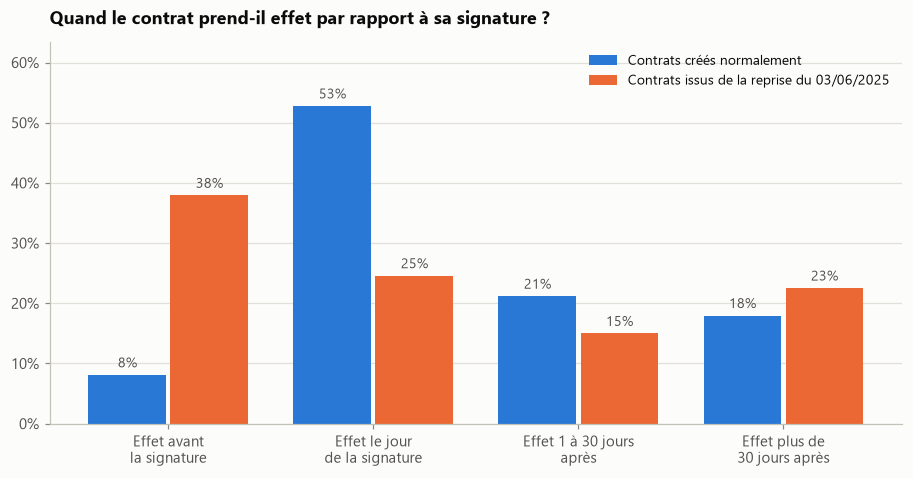

In [54]:
categories = pd.cut(ecart, [-np.inf, -1, 0, 30, np.inf],
                    labels=["Effet avant\nla signature", "Effet le jour\nde la signature",
                            "Effet 1 à 30 jours\naprès", "Effet plus de\n30 jours après"])
origine = np.where(migre, "Contrats issus de la reprise du 03/06/2025", "Contrats créés normalement")
repartition = pd.crosstab(categories, origine, normalize="columns")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(repartition))
largeur = 0.38
for i, (col, couleur) in enumerate(zip(["Contrats créés normalement", "Contrats issus de la reprise du 03/06/2025"],
                                       [PALETTE[0], PALETTE[1]])):
    barres = ax.bar(x + (i - 0.5) * (largeur + 0.02), repartition[col], largeur, color=couleur, label=col)
    ax.bar_label(barres, labels=[f"{v:.0%}" for v in repartition[col]], padding=3, fontsize=9, color=ENCRE["secondaire"])
ax.set_xticks(x, repartition.index)
format_pct(ax, "y")
ax.set_ylim(0, repartition.to_numpy().max() * 1.2)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Quand le contrat prend-il effet par rapport à sa signature ?")
sauver(fig, "p1_ecart_effet_signature")
plt.show()

**Lecture des résultats** : les dates de la table Contrats sont peu fiables.

- **Date de clôture** : elle est remplie pour **tous** les contrats en cours (5 312), alors qu'elle ne devrait l'être que pour les contrats fermés. Si l'on se fiait à elle sans regarder le statut, on compterait 5 312 clients actifs comme perdus.
- **Contrats annulés avant de commencer** : 324 contrats ont été fermés avant leur date d'effet. Ce sont des annulations, à ne compter ni comme clients gagnés ni comme clients perdus.
- **Date de création** : pour 56 % des contrats, elle vaut le 03/06/2025, jour de la reprise des données. Elle ne donne donc pas la vraie date de souscription.
- **Date de signature** : deux fausses dates reviennent des milliers de fois, le 05/08/2024 (2 440 contrats, un lundi) et le 13/08/2021 (484). Elles expliquent les trois quarts des contrats qui semblent prendre effet avant leur signature, comme le montre le graphique.

Ainsi, au niveau de la partie 2, on va utiliser la date de création quand elle est fiable, sinon la date de signature quand ce n'est pas une fausse date afin de connaitre la vraie date de souscription.

Fonction de normalisation des noms de villes

In [55]:
def normaliser_ville(v):
    t = unicodedata.normalize("NFKD", str(v)).encode("ascii", "ignore").decode().upper()
    t = re.sub(r"[^A-Z0-9]+", " ", t).strip()
    t = re.sub(r"\bCEDEX\b.*$", "", t).strip()
    t = re.sub(r"\s+\d+(E|ER|EME)?$", "", t)          # arrondissements : MARSEILLE 05 -> MARSEILLE
    t = re.sub(r"^STE\b", "SAINTE", re.sub(r"^ST\b", "SAINT", t))
    return t or np.nan

Normalisation des villes et enregistrement de l'anomalie C7

In [56]:
villes = contrats_t["address_city"].dropna()
villes_norm = villes.map(normaliser_ville)
print(f"Libellés de ville distincts : {villes.nunique()} bruts, {villes_norm.nunique()} après normalisation")
print("Exemple :", villes[villes_norm == "MARSEILLE"].value_counts().head(6).to_dict())
noter("C7", "Contrats", "Format", "Mineure", "Ville : casse, accents et arrondissements hétérogènes",
      (villes != villes_norm).sum(), len(contrats_t), "Normalisation (majuscules, sans accents, sans arrondissement)")

Libellés de ville distincts : 5353 bruts, 4131 après normalisation
Exemple : {'Marseille': 115, 'MARSEILLE 05': 34, 'MARSEILLE 06': 25, 'MARSEILLE': 20, 'MARSEILLE 01': 20, 'MARSEILLE 04': 19}
[C7] Ville : casse, accents et arrondissements hétérogènes : 5 947 / 12 484 (47.6%)


 Répartition des statuts professionnels

In [57]:
contrats_t["professional_status"].value_counts(dropna=False)

professional_status
NaN               6708
JOB_SEEKER        1541
EMPLOYEE          1323
SELF_EMPLOYED     1312
OTHER              612
STUDENT            315
FONCTIONARY        315
BUSINESS_OWNER     161
INTERIM_WORKER      77
PARENT_AT_HOME      54
RETIRED             35
PRACTITIONER        25
CIVIL_SERVANT        3
STUDENT_PARENT       1
TEMPORARY            1
NOT_MAIN_BENE        1
Name: count, dtype: int64

Enregistrement de l'anomalie C8 : statuts manquants et synonymes

In [58]:
noter("C8", "Contrats", "Complétude", "Majeure",
      "Statut professionnel manquant, avec synonymes (FONCTIONARY / CIVIL_SERVANT, TEMPORARY / INTERIM_WORKER)",
      contrats_t["professional_status"].isna().sum(), len(contrats_t),
      "Harmonisation des libellés, manquants en UNKNOWN")

[C8] Statut professionnel manquant, avec synonymes (FONCTIONARY / CIVIL_SERVANT, TEMPORARY / INTERIM_WORKER) : 6 708 / 12 484 (53.7%)


Sources d'acquisition manquantes et hétérogènes (C9)

In [59]:
print("source (toutes les valeurs) :")
print(contrats_t["source"].value_counts(dropna=False).to_string())
noter("C9", "Contrats", "Complétude", "Majeure",
      "Source d'acquisition manquante, 34 libellés hétérogènes", contrats_t["source"].isna().sum(), len(contrats_t),
      "Regroupement en canaux, manquants en 'Non renseigné'")

source (toutes les valeurs) :
source
NaN                      10025
adwords                   1115
instagram                  472
NC-EmailAvantVente         242
Parrainage                 227
facebook                   136
hs_automation               85
gbp                         37
tiktok                      30
Buddy                       20
email_nc                    19
gabriel                     13
Mool                        10
chatgpt.com                 10
EmailDimancheBienêtre        4
tinder                       4
hs_email                     4
trustpilot                   4
MorganeLombard               3
Ovaira                       3
ANNUAIRE_THERAPEUTES         3
Resalib                      2
nostrumcare                  2
Dailyhack                    2
Flytex                       2
Pemlab                       1
GarryBabaud                  1
Greenwhey                    1
LesEmancipees                1
Biogrine                     1
EmailJourdelAscension        1
La

Autres anomalies mineures de Contrats : souscripteurs et bénéficiaires (C10 à C14)

In [60]:
age_signature = (cu["signature_date"] - cu["birthdate"]).dt.days / 365.25
noter("C10", "Contrats", "Cohérence", "Mineure", "Souscripteur principal mineur à la signature",
      (age_signature < 18).sum(), len(cu), "Signalement (flag_mineur)")
noter("C11", "Contrats", "Cohérence", "Mineure",
      "Type de bénéficiaire ADULT dans une table de souscripteurs principaux",
      (contrats_t["beneficiary_individual_type"] != "PRIMARY_SUBSCRIBER").sum(), len(contrats_t), "Conservé tel quel, documenté")
liste_vide = liste_benef.str.len() == 0
noter("C12", "Contrats", "Complétude", "Mineure", "Liste des bénéficiaires manquante ou vide",
      liste_vide.sum(), len(contrats_t), "Le souscripteur est compté comme unique bénéficiaire")
hors_liste = ~liste_vide & np.array([b not in l for b, l in zip(contrats_t["beneficiary_id"], liste_benef)])
noter("C13", "Contrats", "Cohérence", "Mineure", "Souscripteur absent de sa propre liste de bénéficiaires",
      hors_liste.sum(), len(contrats_t), "Ajouté à la table pont des bénéficiaires")
print("  dont lignes appartenant à un Contrat_id dupliqué :", (hors_liste & contrats_t["contract_id"].isin(ids_dupliques.index)).sum())
noter("C14", "Contrats", "Format", "Mineure", "Colonne frequency constante (MONTHLY partout)",
      len(contrats_t), len(contrats_t), "Colonne supprimée")

[C10] Souscripteur principal mineur à la signature : 13 / 12 216 (0.1%)
[C11] Type de bénéficiaire ADULT dans une table de souscripteurs principaux : 5 / 12 484 (0.0%)
[C12] Liste des bénéficiaires manquante ou vide : 56 / 12 484 (0.4%)
[C13] Souscripteur absent de sa propre liste de bénéficiaires : 296 / 12 484 (2.4%)
  dont lignes appartenant à un Contrat_id dupliqué : 264
[C14] Colonne frequency constante (MONTHLY partout) : 12 484 / 12 484 (100.0%)


#### Stripe

Incohérences de statut et transactions en double dans Stripe (S3 à S6)

In [61]:
print(pd.crosstab(stripe_t["status"], stripe_t["captured"], margins=True, margins_name="total"))
echec_capture = (stripe_t["status"] == "Failed") & stripe_t["captured"]
noter("S3", "Stripe", "Cohérence", "Majeure", "Paiement en échec mais marqué comme capturé",
      echec_capture.sum(), len(stripe_t), "Le statut fait foi (un motif de refus est présent) : captured corrigé")
noter("S4", "Stripe", "Cohérence", "Mineure", "Paiement réussi avec un motif de refus",
      ((stripe_t["status"] == "Paid") & stripe_t["decline_reason"].notna()).sum(), len(stripe_t), "Conservé, documenté")
noter("S5", "Stripe", "Cohérence", "Mineure", "Montant converti nul alors que le montant est positif",
      ((stripe_t["converted_amount"] <= 0) & (stripe_t["amount"] > 0)).sum(), len(stripe_t),
      "Colonne convertie supprimée (devise unique : eur)")
doublon_tx = stripe_t.duplicated(["contract_id", "created_at", "amount", "status"])
noter("S6", "Stripe", "Doublon", "Mineure", "Transactions en double (même contrat, même seconde, même montant)",
      doublon_tx.sum(), len(stripe_t), "Suppression")

captured  False    True   total
status                         
Failed    30680     641   31321
Paid          0  132541  132541
Pending       0     496     496
Refunded      0    2015    2015
total     30680  135693  166373
[S3] Paiement en échec mais marqué comme capturé : 641 / 166 373 (0.4%)
[S4] Paiement réussi avec un motif de refus : 3 / 166 373 (0.0%)
[S5] Montant converti nul alors que le montant est positif : 4 / 166 373 (0.0%)
[S6] Transactions en double (même contrat, même seconde, même montant) : 7 / 166 373 (0.0%)


 Paiements encaissés plusieurs fois le même jour : double prélèvement ou rattrapage d'impayés ? (S7)

In [62]:
# Paiements multiples rapprochés : même contrat, même montant, même jour, tous encaissés

st = stripe_t.loc[~doublon_tx].copy()
st["jour"] = st["created_at"].dt.normalize()
encaisse = st["status"] == "Paid"
multiple = encaisse & st.duplicated(["contract_id", "amount", "jour", "status"], keep="first")
groupes_multi = st.loc[encaisse & st.duplicated(["contract_id", "amount", "jour", "status"], keep=False)]
ecart_min = groupes_multi.groupby(["contract_id", "amount", "jour"])["created_at"].agg(lambda x: (x.max() - x.min()).total_seconds() / 60)

# Le contrat avait-il des échecs de paiement dans les 90 jours précédents (rattrapage d'impayés) ?

echecs = st.loc[st["status"] == "Failed", ["contract_id", "created_at"]]
cand = st.loc[multiple, ["contract_id", "created_at"]].reset_index()
fusion = cand.merge(echecs, on="contract_id", suffixes=("", "_echec"))
fusion = fusion[(fusion["created_at_echec"] < fusion["created_at"]) &
                (fusion["created_at_echec"] >= fusion["created_at"] - pd.Timedelta(days=90))]
part_rattrapage = fusion["index"].nunique() / len(cand)

noter("S7", "Stripe", "Doublon", "Majeure",
      "Paiements multiples encaissés le même jour pour le même montant (double prélèvement ou rattrapage d'impayés)",
      multiple.sum(), encaisse.sum(), "Signalement (flag_paiement_multiple), à faire valider par la finance",
      montant=float(st.loc[multiple, "amount"].sum()))
print(f"  écart médian entre paiements d'un même groupe : {ecart_min.median():.1f} minutes")
print(f"  {part_rattrapage:.0%} précédés d'un échec de paiement dans les 90 jours (rattrapage d'impayés probable)")

[S7] Paiements multiples encaissés le même jour pour le même montant (double prélèvement ou rattrapage d'impayés) : 1 449 / 132 541 (1.1%) | 82 470 €
  écart médian entre paiements d'un même groupe : 0.6 minutes
  46% précédés d'un échec de paiement dans les 90 jours (rattrapage d'impayés probable)


Paiements en attente et colonnes inutiles de Stripe (S8)

In [63]:
en_attente = stripe_t["status"] == "Pending"
anciennete = (DATE_EXTRACTION - stripe_t.loc[en_attente, "created_at"]).dt.days
print("Ancienneté des paiements en attente (jours) :", anciennete.describe()[["min", "50%", "max"]].round(0).to_dict(),
      "-> tous récents, pas d'anomalie")
noter("S8", "Stripe", "Format", "Mineure",
      "Colonnes constantes ou redondantes (Currency, Converted Currency, Converted Amount*, Statement Descriptor)",
      len(stripe_t), len(stripe_t), "Colonnes supprimées")

Ancienneté des paiements en attente (jours) : {'min': 13.0, '50%': 17.0, 'max': 20.0} -> tous récents, pas d'anomalie
[S8] Colonnes constantes ou redondantes (Currency, Converted Currency, Converted Amount*, Statement Descriptor) : 166 373 / 166 373 (100.0%)


**Lecture des résultats**

- **641 paiements en échec sont marqués « capturés »** : tous ont un motif de refus bancaire, donc le statut fait foi et `captured` est corrigé.
- **1 449 paiements sont encaissés plusieurs fois le même jour, pour le même montant (82 470 €)**, à 0,6 minute d'intervalle en médiane :
  - 46 % suivent un échec de paiement dans les 90 jours : probable rattrapage d'impayés (plusieurs échéances prélevées d'un coup) ;
  - les 54 % restants sont de possibles **doubles prélèvements**, à vérifier par la finance avec les identifiants de transaction Stripe, absents du fichier (X2).

#### Remboursements

Montants et dates de décision des remboursements (R6 à R10)

In [64]:
rv = remb_valides.drop_duplicates()
approuve = rv["is_approved"] == 1
refuse = rv["is_approved"] == 0
rembourse = rv["amount_refund_mutual"]

print(pd.crosstab(rv["reason"].fillna("(aucun motif)"), rv["is_approved"].map({0: "refusé", 1: "approuvé"})))
noter("R6", "Remboursements", "Complétude", "Majeure", "Remboursement approuvé sans montant remboursé",
      (approuve & rembourse.isna()).sum(), approuve.sum(), "Signalement (flag_montant_manquant), exclu des sommes")
print("  approuvés avec un montant à 0 :", (approuve & (rembourse == 0)).sum())
noter("R7", "Remboursements", "Cohérence", "Mineure", "Remboursement refusé avec un montant positif",
      (refuse & (rembourse > 0)).sum(), refuse.sum(), "Signalement (flag_montant_incoherent)")

calculable = approuve & rembourse.notna() & rv["amount_request"].notna() & rv["rest_to_pay"].notna()
ecart_formule = (rembourse - (rv["amount_request"] - rv["rest_to_pay"])).abs() > 0.01
noter("R8", "Remboursements", "Cohérence", "Mineure",
      "Montant remboursé différent de (montant demandé - reste à charge)",
      (calculable & ecart_formule).sum(), calculable.sum(), "Conservé, documenté (règles de calcul à confirmer)")
noter("R9", "Remboursements", "Valeur extrême", "Mineure", "Montant remboursé supérieur à 500 €",
      (rembourse > 500).sum(), rembourse.notna().sum(), "Signalement (flag_montant_extreme), à contrôler")
print("  médiane des montants remboursés :", rembourse.median(), "€ | maximum :", rembourse.max(), "€")

meme_jour = (rv["approved_date"].dt.normalize() == rv["created_at"].dt.normalize())
noter("R10", "Remboursements", "Complétude", "Majeure",
      "Date de décision toujours égale au jour de création : délai de traitement non mesurable",
      meme_jour.sum(), len(rv), "Documenté (impacte la question 2.2)")
print("  heures de création :", rv["created_at"].dt.hour.value_counts().sort_index().loc[8:17].to_dict())

is_approved                         approuvé  refusé
reason                                              
(aucun motif)                          42097    1513
100_REFUND_BY_SS                           0     155
A DONNER A CPAM                            0     173
ACT_EPUISE                                 0    1079
ALEA                                       0      59
APPROVED                                 172       0
DATE DEBUT CONTRAT                         0     385
DATE FIN CONTRAT                           0     413
DECLINED_ESTIMATE                          0     274
DECOMPTE DATE SOIN < DATE ADHESION         0     163
EXCESS_FEES                                0     344
FRAUDULENT                                 0       2
FULL_POT                                   0    1140
HN                                         0     310
NOT_COVERED                                0    1660
PAIEMENT TIER ---> ADH                     0      13
PHARMACIE NON PRIS EN CHARGE               0  

##### **Lecture des résultats**

**Dates**
- La date de décision (`approved_date`) tombe **toujours le même jour** que la date de création (`created_at`).
- Les créations ont lieu presque toutes entre 9 h et 16 h, aux heures de bureau.
- `created_at` correspond donc au moment où **un gestionnaire traite la demande**, et non au moment où l'adhérent l'envoie. On remarque donc que le vrai délai de remboursement n'est pas mesurable.

**Montants**
- 1 047 remboursements approuvés (2,5 %) **n'ont pas de montant** : les sommes remboursées sont donc légèrement sous-estimées.
- Pour 16 % des remboursements, le montant remboursé ne vaut pas « montant demandé moins reste à charge ». Des plafonds ou des forfaits peuvent l'expliquer, à confirmer avec le métier.

#### Produits

 Nom de produit en double et produits réellement utilisés (P1)

In [65]:
print(produits_brut[produits_brut["name"].duplicated(keep=False)].to_string())
noter("P1", "Produits", "Doublon", "Mineure", "Nom de produit en double (IJHA 15, deux univers différents)",
      produits_brut["name"].duplicated().sum(), len(produits_brut), "Conservé : deux identifiants distincts")
print("\nProduits utilisés dans les contrats :", contrats_t["product_id"].nunique(), "sur", len(produits_brut))

                                      id     name insurer     universe           type
13  66864644-e993-46d8-8234-320cdb065155  IJHA 15     MMC         LIFE         MUTUAL
34  adef6242-d79f-40f9-b9d2-992fb46a200d  IJHA 15     MMC  CONTINGENCY  SUPPLEMENTARY
[P1] Nom de produit en double (IJHA 15, deux univers différents) : 1 / 58 (1.7%)

Produits utilisés dans les contrats : 9 sur 58


## 4. Analyse chiffrée des anomalies

### 4.1 Registre complet

In [66]:
ordre_gravite = {"Critique": 0, "Majeure": 1, "Mineure": 2}
reg = pd.DataFrame(registre)
reg = reg.assign(_o=reg["gravité"].map(ordre_gravite)).sort_values(["_o", "lignes"], ascending=[True, False]).drop(columns="_o")
print(f"{len(reg)} anomalies recensées :", reg["gravité"].value_counts().reindex(ordre_gravite).to_dict())
reg.style.format({"part": "{:.1%}", "lignes": "{:,.0f}", "base": "{:,.0f}", "montant (€)": "{:,.0f}"},
                 na_rep="", thousands=" ").hide(axis="index")

47 anomalies recensées : {'Critique': 5, 'Majeure': 23, 'Mineure': 19}


code,tables,famille,gravité,description,lignes,base,part,montant (€),traitement
X11,Stripe ↔ Contrats,Cohérence temporelle,Critique,Paiement encaissé plus de 31 jours après la clôture du contrat,1 446,132 108,1.1%,95 110,Signalement (flag_apres_cloture) : encaissement indu ou date de clôture erronée
X5,Contrats → Stripe,Intégrité référentielle,Critique,Contrats dont toutes les transactions Stripe ont échoué (aucune cotisation encaissée),889,12 216,7.3%,,Signalement (flag_jamais_encaisse)
X3,Stripe → Contrats,Intégrité référentielle,Critique,Paiements Stripe rattachés à un contrat absent de Contrats,793,166 373,0.5%,43 796,"Signalement (flag_contrat_inconnu), exclus des analyses croisées"
X14,Remboursements ↔ Stripe,Cohérence métier,Critique,Remboursement approuvé sur un contrat sans aucune cotisation encaissée,456,41 890,1.1%,17 366,Signalement (flag_contrat_jamais_encaisse)
X1,"Contrats ↔ Stripe, Remboursements",Clé,Critique,Contrat_id non unique,268,12 484,2.1%,121 876,"Une ligne par contrat (souscripteur présent dans la liste des bénéficiaires, sinon le plus récent) ; autres beneficiary_id gardés dans une table pont"
X2,"Stripe, Remboursements",Clé,Majeure,Aucun identifiant de ligne,221 895,221 895,100.0%,,Création d'un identifiant technique après nettoyage
R10,Remboursements,Complétude,Majeure,Date de décision toujours égale au jour de création : délai de traitement non mesurable,53 219,53 221,100.0%,,Documenté (impacte la question 2.2)
X10,Stripe ↔ Contrats,Cohérence temporelle,Majeure,Paiement encaissé plus de 31 jours avant la signature du contrat,11 738,132 108,8.9%,,"Signalement (flag_avant_signature) : la date de signature n'est pas fiable (voir C3, C5)"
C9,Contrats,Complétude,Majeure,"Source d'acquisition manquante, 34 libellés hétérogènes",10 025,12 484,80.3%,,"Regroupement en canaux, manquants en 'Non renseigné'"
C4,Contrats,Cohérence,Majeure,created_at égal à la date de reprise du 03/06/2025 (pas une vraie date de création),6 869,12 216,56.2%,,Signalement (flag_migration) ; signature_date utilisée comme date de souscription


### 4.2 Contrôles conformes

Voici ce qui a été vérifié et s'est révélé correct : sans cette liste, on ne saurait pas distinguer un point juste d'un point non contrôlé.

In [67]:
conformes = pd.DataFrame([
    ("Produit des contrats présent dans Produits", controle_produits.at[0, "produit_inconnu_contrats"] == 0),
    ("Produit des paiements Stripe présent dans Produits", controle_produits.at[0, "produit_inconnu_stripe"] == 0),
    ("Produit d'un paiement identique au produit du contrat", controle_produits.at[0, "produit_different_du_contrat"] == 0),
    ("Montant remboursé par Stripe <= montant payé", (stripe_t["amount_refunded"] <= stripe_t["amount"]).all()),
    ("Date de remboursement Stripe >= date de paiement", ((stripe_t["refunded_at"] >= stripe_t["created_at"]) | stripe_t["refunded_at"].isna()).all()),
    ("Aucun montant négatif (Stripe, Remboursements)", (stripe_t["amount"] >= 0).all() and (rv[COLS_MONTANTS + ["amount_refund_mutual"]].min() >= 0).all()),
    ("Montant remboursé par la mutuelle <= montant demandé", ~((rembourse > rv["amount_request"] + 0.01)).any()),
    ("Date de naissance plausible (1933-2008)", contrats_t["birthdate"].dropna().between("1900-01-01", "2010-12-31").all()),
    ("Aucune date de signature dans le futur", (contrats_t["signature_date"] <= DATE_EXTRACTION).all()),
    ("Aucun doublon exact parmi les demandes de remboursement valides", not remb_valides.duplicated().any()),
    ("Aucune date de demande postérieure à l'extraction (lignes valides)", (remb_valides["created_at"] <= DATE_EXTRACTION + pd.Timedelta(days=1)).all()),
    ("Paiements en attente tous récents (moins de 30 jours)", (anciennete <= 30).all()),
    ("Un motif de refus pour chaque paiement en échec", stripe_t.loc[stripe_t["status"] == "Failed", "decline_reason"].notna().all()),
], columns=["contrôle", "conforme"])
conformes

,contrôle,conforme
0,Produit des contrats présent dans Produits,True
1,Produit des paiements Stripe présent dans Produits,True
2,Produit d'un paiement identique au produit du contrat,True
3,Montant remboursé par Stripe <= montant payé,True
4,Date de remboursement Stripe >= date de paiement,True
5,"Aucun montant négatif (Stripe, Remboursements)",True
6,Montant remboursé par la mutuelle <= montant demandé,True
7,Date de naissance plausible (1933-2008),True
8,Aucune date de signature dans le futur,True
9,Aucun doublon exact parmi les demandes de remboursement valides,True


### 4.3 Vue de synthèse

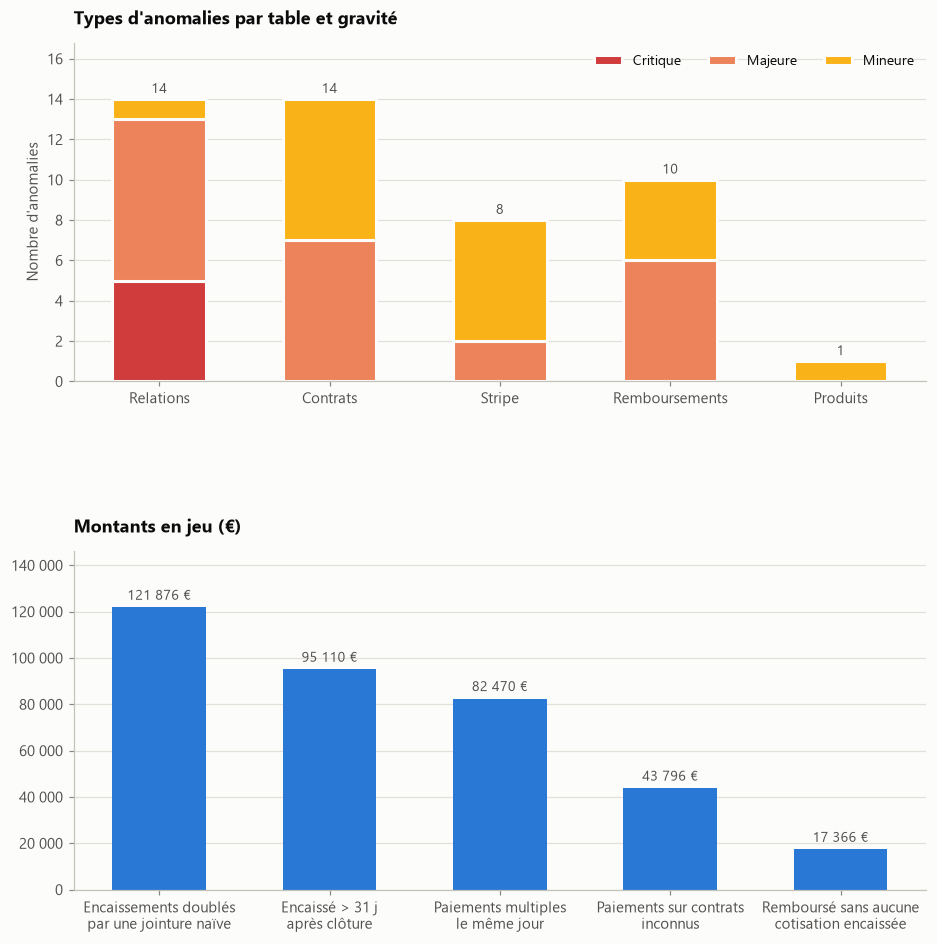

In [68]:
reg["table principale"] = reg["code"].str[0].map({"X": "Relations", "C": "Contrats", "S": "Stripe", "R": "Remboursements", "P": "Produits"})
synthese = reg.pivot_table(index="table principale", columns="gravité", values="code", aggfunc="count", fill_value=0)
synthese = synthese.reindex(index=["Relations", "Contrats", "Stripe", "Remboursements", "Produits"], columns=["Critique", "Majeure", "Mineure"], fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={"hspace": 0.5})

# Graphique 1 : nombre d'anomalies par table, empilées par gravité
ax = axes[0]
bas = np.zeros(len(synthese))
for grav in synthese.columns:
    ax.bar(synthese.index, synthese[grav], bottom=bas, width=0.55, color=STATUT[grav.lower()], label=grav,
           edgecolor=ENCRE["fond"], linewidth=2)
    bas += synthese[grav].to_numpy()
for i, total in enumerate(synthese.sum(axis=1)):
    ax.annotate(str(total), (i, total), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=ENCRE["secondaire"])
ax.set_ylim(0, synthese.sum(axis=1).max() * 1.2)
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper right")
ax.set_ylabel("Nombre d'anomalies")
ax.set_title("Types d'anomalies par table et gravité")

# Graphique 2 : montants en jeu, du plus grand au plus petit
ax = axes[1]
enjeux = reg.dropna(subset=["montant (€)"]).sort_values("montant (€)", ascending=False)
libelles = {"X1": "Encaissements doublés\npar une jointure naïve", "X3": "Paiements sur contrats\ninconnus",
            "X11": "Encaissé > 31 j\naprès clôture", "X14": "Remboursé sans aucune\ncotisation encaissée",
            "S7": "Paiements multiples\nle même jour"}
ax.bar(enjeux["code"].map(libelles), enjeux["montant (€)"], width=0.55, color=PALETTE[0])
etiqueter_barres(ax, enjeux["montant (€)"], fmt="{:,.0f} €", horizontal=False)
ax.set_ylim(0, enjeux["montant (€)"].max() * 1.2)
format_milliers(ax, "y")
ax.grid(axis="x", visible=False)
ax.set_title("Montants en jeu (€)")

sauver(fig, "p1_synthese_anomalies")
plt.show()

##### **Lecture des résultats**

Chaque table, prise seule, est utilisable. Les problèmes graves apparaissent quand on les croise : contrats en double, paiements sans contrat, encaissements après la fin du contrat, remboursements sans cotisation. Au total, **plusieurs centaines de milliers d'euros** sont mal rattachés ou à vérifier (un même paiement pouvant compter dans plusieurs anomalies, les montants ne s'additionnent pas).

## 5. Nettoyage

### 5.1 Contrats et table pont des bénéficiaires

In [69]:
STATUTS_PRO = {"FONCTIONARY": "CIVIL_SERVANT", "TEMPORARY": "INTERIM_WORKER", "STUDENT_PARENT": "STUDENT", "NOT_MAIN_BENE": np.nan}

def canal_acquisition(source):
    if pd.isna(source):
        return "Non renseigné"
    s = str(source).lower()
    if re.search(r"adwords|google|gads|sea\b|bing", s):
        return "Publicité moteur de recherche"
    if re.search(r"instagram|facebook|tiktok|meta|snap|linkedin|youtube|tinder|pinterest", s):
        return "Réseaux sociaux"
    if re.search(r"parrain|buddy|referral", s):
        return "Parrainage"
    if re.search(r"mail|newsletter|hs_|hubspot|crm|sms", s):
        return "Email / CRM"
    if re.search(r"gbp|chatgpt|seo|organic|trustpilot|nostrumcare", s):
        return "Organique (fiche Google, IA, avis, site)"
    
    # annuaires de praticiens, marques partenaires, influenceurs (gabriel, Mool, Resalib, ...)

    return "Partenaires et influenceurs"

c = contrats_t.copy()
c["liste_beneficiaires"] = liste_benef
c["souscripteur_dans_liste"] = [b in l for b, l in zip(c["beneficiary_id"], c["liste_beneficiaires"])]
c["flag_id_duplique"] = c["contract_id"].duplicated(keep=False)

# Table pont : tous les bénéficiaires de chaque contrat, y compris les souscripteurs des lignes dupliquées

beneficiaires = beneficiaires_t.copy()

# Dédoublonnage : souscripteur présent dans la liste en priorité, puis le plus récent

c = (c.sort_values(["contract_id", "souscripteur_dans_liste", "created_at"], ascending=[True, False, False])
      .drop_duplicates("contract_id", keep="first"))
cles_souscripteur = pd.MultiIndex.from_frame(c[["contract_id", "beneficiary_id"]])
beneficiaires["est_souscripteur"] = pd.MultiIndex.from_frame(beneficiaires[["contract_id", "beneficiary_id"]]).isin(cles_souscripteur)

c["est_ferme"] = c["status_contrat"] == "Contrat Fermé"
c.loc[~c["est_ferme"], "closed_date"] = pd.NaT
c["flag_annule_avant_effet"] = c["est_ferme"] & (c["closed_date"] < c["start_date"])
c["flag_debut_avant_signature"] = c["start_date"] < c["signature_date"]
c["flag_migration"] = c["created_at"].dt.normalize() == DATE_MIGRATION
c["flag_signature_par_defaut"] = c["signature_date"].isin(DATES_SIGNATURE_DEFAUT)
c["flag_effet_futur"] = c["start_date"] > DATE_EXTRACTION

zip_ok = c["address_zip"].where(c["address_zip"] >= 1000)
c["address_zip"] = zip_ok.map(lambda z: f"{int(z):05d}" if pd.notna(z) else np.nan)
c["departement"] = c["address_zip"].map(lambda z: (z[:3] if z.startswith("97") else z[:2]) if isinstance(z, str) else np.nan)
c["address_city"] = c["address_city"].map(lambda v: normaliser_ville(v) if pd.notna(v) else np.nan)

c["professional_status"] = c["professional_status"].replace(STATUTS_PRO).fillna("UNKNOWN")
c["canal_acquisition"] = c["source"].map(canal_acquisition)
c["age_souscription"] = ((c["signature_date"] - c["birthdate"]).dt.days / 365.25).round(1)
c["age"] = ((DATE_EXTRACTION - c["birthdate"]).dt.days / 365.25).round(1)
c["flag_mineur"] = c["age_souscription"] < 18
c["nb_beneficiaires"] = [len(set(l) | {b}) for l, b in zip(c["liste_beneficiaires"], c["beneficiary_id"])]
c = c.merge(produits_brut[["id", "name"]].rename(columns={"id": "product_id", "name": "product_name"}), on="product_id", how="left")

print(c["canal_acquisition"].value_counts().to_string())

canal_acquisition
Non renseigné                               9852
Publicité moteur de recherche               1057
Réseaux sociaux                              628
Email / CRM                                  348
Parrainage                                   233
Organique (fiche Google, IA, avis, site)      51
Partenaires et influenceurs                   47


### 5.2 Stripe

In [70]:
s = stripe_t.loc[~doublon_tx].drop(columns=["converted_amount"]).copy()
s = s.sort_values(["contract_id", "created_at"]).reset_index(drop=True)
s.insert(0, "payment_id", np.arange(1, len(s) + 1))
# S3
s["captured"] = s["status"].isin(["Paid", "Refunded"])            
s["montant_net"] = np.where(s["captured"], s["amount"] - s["amount_refunded"], 0.0)

s["flag_contrat_inconnu"] = ~s["contract_id"].isin(c["contract_id"])
s["jour"] = s["created_at"].dt.normalize()
s["flag_paiement_multiple"] = (s["status"] == "Paid") & s.duplicated(["contract_id", "amount", "jour", "status"], keep="first")
s = s.drop(columns="jour")

dates_contrat = c.set_index("contract_id")[["signature_date", "closed_date"]]
s = s.join(dates_contrat, on="contract_id")
s["flag_avant_signature"] = (s["status"] == "Paid") & (s["created_at"] < s["signature_date"] - pd.Timedelta(days=31))
s["flag_apres_cloture"] = (s["status"] == "Paid") & (s["created_at"] > s["closed_date"] + pd.Timedelta(days=31))
s = s.drop(columns=["signature_date", "closed_date"])

# Indicateurs relationnels côté contrat

agg = s.groupby("contract_id").agg(nb_transactions=("payment_id", "size"),
                                   nb_paiements_encaisses=("status", lambda x: (x == "Paid").sum()),
                                   montant_encaisse=("montant_net", "sum"), nb_echecs=("status", lambda x: (x == "Failed").sum()))
c = c.join(agg, on="contract_id")
c[["nb_transactions", "nb_paiements_encaisses", "nb_echecs"]] = c[["nb_transactions", "nb_paiements_encaisses", "nb_echecs"]].fillna(0).astype(int)
c["montant_encaisse"] = c["montant_encaisse"].fillna(0.0)
c["flag_sans_transaction"] = c["nb_transactions"] == 0
c["flag_jamais_encaisse"] = (c["nb_transactions"] > 0) & (c["nb_paiements_encaisses"] == 0)
s[["status", "captured"]].value_counts()

status    captured
Paid      True        132541
Failed    False        31321
Refunded  True          2008
Pending   False          496
Name: count, dtype: int64

### 5.3 Remboursements

Quand le `contract_id` est absent ou inconnu, on le déduit du bénéficiaire **uniquement si celui-ci n'appartient qu'à un seul contrat** (sinon l'attribution serait arbitraire).

In [71]:
r = remb_valides.drop_duplicates().copy()
r = r.sort_values("created_at").reset_index(drop=True)
r.insert(0, "claim_id", np.arange(1, len(r) + 1))
r["is_approved"] = r["is_approved"].astype(int)

ids_contrats = set(c["contract_id"])
contrat_valide = r["contract_id"].isin(ids_contrats)
nb_contrats_par_benef = beneficiaires.groupby("beneficiary_id")["contract_id"].agg(["nunique", "first"])
contrat_unique = nb_contrats_par_benef.loc[nb_contrats_par_benef["nunique"] == 1, "first"]
deduit = r["beneficiary_id"].map(contrat_unique)

r["source_contract_id"] = np.select(
    [contrat_valide, deduit.notna()], ["origine", "déduit du bénéficiaire"], default="non rattaché")
r["contract_id"] = r["contract_id"].where(contrat_valide, deduit)
print(r["source_contract_id"].value_counts().to_string())

r = r.merge(c[["contract_id", "user_id", "start_date", "closed_date", "est_ferme", "flag_sans_transaction", "flag_jamais_encaisse"]],
            on="contract_id", how="left")
paires = pd.MultiIndex.from_frame(beneficiaires[["contract_id", "beneficiary_id"]])
r["flag_beneficiaire_inconnu"] = r["beneficiary_id"].notna() & ~r["beneficiary_id"].isin(beneficiaires["beneficiary_id"])
r["flag_beneficiaire_hors_contrat"] = (r["contract_id"].notna() & ~r["flag_beneficiaire_inconnu"]
                                      & ~pd.MultiIndex.from_frame(r[["contract_id", "beneficiary_id"]]).isin(paires))
r["flag_montant_manquant"] = (r["is_approved"] == 1) & r["amount_refund_mutual"].isna()
r["flag_montant_incoherent"] = (r["is_approved"] == 0) & (r["amount_refund_mutual"] > 0)
r["flag_montant_extreme"] = r["amount_refund_mutual"] > 500
r["flag_avant_effet"] = (r["is_approved"] == 1) & (r["created_at"] < r["start_date"])
r["flag_apres_cloture_90j"] = (r["is_approved"] == 1) & r["est_ferme"].fillna(False) & (r["created_at"] > r["closed_date"] + pd.Timedelta(days=90))
r["flag_contrat_jamais_encaisse"] = (r["is_approved"] == 1) & r["contract_id"].notna() & (r["flag_sans_transaction"] | r["flag_jamais_encaisse"]).fillna(False)
r = r.drop(columns=["start_date", "closed_date", "est_ferme", "flag_sans_transaction", "flag_jamais_encaisse"])
r.filter(like="flag_").sum().to_frame("lignes signalées")

source_contract_id
origine                   46822
déduit du bénéficiaire     6241
non rattaché                158


,lignes signalées
flag_beneficiaire_inconnu,286
flag_beneficiaire_hors_contrat,16
flag_montant_manquant,1047
flag_montant_incoherent,3
flag_montant_extreme,58
flag_avant_effet,13
flag_apres_cloture_90j,390
flag_contrat_jamais_encaisse,460


##### **Lecture des résultats** 

Le rattachement par le bénéficiaire récupère 6 241 des 6 399 demandes sans contrat valide. Il ne reste que **158 demandes non rattachées** (0,3 %), contre 12 % avant nettoyage.

### 5.4 Produits, contrôles finaux et export

In [72]:
p = produits_brut.rename(columns={"id": "product_id"}).copy()
p["flag_nom_duplique"] = p["name"].duplicated(keep=False)
p["nb_contrats"] = p["product_id"].map(c["product_id"].value_counts()).fillna(0).astype(int)

contrats = c.drop(columns=["frequency", "list_beneficiaries_id", "liste_beneficiaires", "souscripteur_dans_liste"])
stripe = s
remboursements = r
produits = p

# Contrôles post-nettoyage : ils doivent tous passer

assert contrats["contract_id"].is_unique
assert stripe["payment_id"].is_unique and remboursements["claim_id"].is_unique
assert stripe[["amount", "amount_refunded", "created_at"]].notna().all().all()
assert remboursements["created_at"].notna().all() and remboursements["is_approved"].isin([0, 1]).all()
assert contrats.loc[~contrats["est_ferme"], "closed_date"].isna().all()
assert set(stripe.loc[~stripe["flag_contrat_inconnu"], "contract_id"]) <= set(contrats["contract_id"])
assert set(remboursements["contract_id"].dropna()) <= set(contrats["contract_id"])
assert not remboursements.drop(columns="claim_id").duplicated().any()
print("Tous les contrôles post-nettoyage passent.")

bilan = pd.DataFrame({
    "lignes brutes": [len(contrats_brut), len(stripe_brut), len(remb_brut), len(produits_brut)],
    "lignes propres": [len(contrats), len(stripe), len(remboursements), len(produits)],
    "colonnes propres": [contrats.shape[1], stripe.shape[1], remboursements.shape[1], produits.shape[1]],
    "lignes avec au moins un flag": [contrats.filter(like="flag_").any(axis=1).sum(), stripe.filter(like="flag_").any(axis=1).sum(),
                                     remboursements.filter(like="flag_").any(axis=1).sum(), produits.filter(like="flag_").any(axis=1).sum()],
}, index=["Contrats", "Stripe", "Remboursements", "Produits"])
bilan["lignes supprimées"] = bilan["lignes brutes"] - bilan["lignes propres"]
bilan["part supprimée"] = bilan["lignes supprimées"] / bilan["lignes brutes"]
bilan.style.format({"part supprimée": "{:.1%}"}, thousands=" ")

Tous les contrôles post-nettoyage passent.


,lignes brutes,lignes propres,colonnes propres,lignes avec au moins un flag,lignes supprimées,part supprimée
Contrats,12 484,12 216,37,8 619,268,2.1%
Stripe,166 373,166 366,17,15 211,7,0.0%
Remboursements,55 522,53 221,22,2 206,2 301,4.1%
Produits,58,58,7,2,0,0.0%


In [73]:
DOSSIER_PROPRE.mkdir(parents=True, exist_ok=True)
for nom, df in {"contrats": contrats, "beneficiaires": beneficiaires, "stripe": stripe,
                "remboursements": remboursements, "produits": produits}.items():
    df.to_pickle(DOSSIER_PROPRE / f"{nom}.pkl")
    df.to_csv(DOSSIER_PROPRE / f"{nom}.csv", index=False)
reg.drop(columns="table principale").to_csv(DOSSIER_PROPRE / "registre_anomalies.csv", index=False)
print("Exporté dans", DOSSIER_PROPRE.relative_to(Path.cwd().parent))
print(sorted(f.name for f in DOSSIER_PROPRE.iterdir()))

Exporté dans data\processed
['beneficiaires.csv', 'beneficiaires.pkl', 'contrats.csv', 'contrats.pkl', 'produits.csv', 'produits.pkl', 'registre_anomalies.csv', 'remboursements.csv', 'remboursements.pkl', 'segments_clients.csv', 'stripe.csv', 'stripe.pkl']


## 6. Synthèse de la partie 1

**Ce que j'ai constaté**

1. **Les tables sont utilisables séparément, mais leurs liens posent problème.** Des contrats en double faussent toute jointure (121 876 € comptés deux fois), 793 paiements portent sur des contrats inconnus, 1 446 sont encaissés plus d'un mois après la fin du contrat (95 110 €), et 456 remboursements ont été versés à des contrats qui n'ont jamais cotisé.
2. **Les dates sont peu fiables.** La reprise de 2025 a écrasé la date de création de 56 % des contrats, 24 % des dates de signature sont fausses, et la date de clôture est remplie même pour les contrats en cours.
3. **J'ai nettoyé sans perdre d'information.** Je n'ai supprimé que les doublons et les lignes inexploitables (2,1 % des contrats, 4,1 % des remboursements). Tout le reste est corrigé ou signalé.

**Mes choix pour la partie 2**

- Un client est un `user_id`, et chaque contrat n'apparaît qu'une fois.
- La date de souscription est la date de création quand elle est fiable, sinon la date de signature quand ce n'est pas une fausse date.
- Les contrats annulés avant de commencer ne comptent ni comme gagnés ni comme perdus.
